In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.stats import poisson
import pandas as pd
import seaborn as sns

#from IPython.display import set_matplotlib_formats
#%config InlineBackend.figure_formats = ['svg', 'pdf']

np.set_printoptions(precision=4)

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [3]:
# Standarize font
plt.rcParams['font.sans-serif'] 
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial"]

In [41]:
import warnings
warnings.filterwarnings('ignore')

## Setting up dynamics

In [4]:
# Define the starting value for testing
haplo_freq = np.array([0.5, 0.5, 0, 0])

# Define model parameters
epi_vec = np.array([0.021, 0.042, 0.084])     # epistasis, g1, g2, g4
overdom_vec = np.array([0.02, 0.02]) # overdominance (as alpha, beta)
mig_vec = np.array([0.02, 0.05])     # migration
rec = 0.01                      # recombination

# Define selection matrix for all 16 possible combinations of gametes (from mom and dad)
selection_mat = np.array([
    [1, 1 + overdom_vec[0], 1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0])],
    [1 + overdom_vec[0], 1, (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1])],
    [1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), 1, (1 + overdom_vec[1]) * (1 - epi_vec[1])],
    [(1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1]), (1 + overdom_vec[1]) * (1 - epi_vec[1]), 1 - epi_vec[2]]
])

# Print the selection matrix
print("Selection Matrix:")
print(selection_mat)

# Migration step (if zygotes arrive)
haplo_freq = haplo_freq * (1 - np.sum(mig_vec)) + np.array([0, mig_vec[0], mig_vec[1], 0])
print("Freq after migration")
print(haplo_freq)


# Random mating creates genotypes
geno_mat = np.outer(haplo_freq, haplo_freq)

# Selection step: multiply with selection table and renormalize by mean fitness
selection = selection_mat * geno_mat
fit_mean = np.sum(selection)
geno_mat = selection / fit_mean

# Print genotype frequency matrix
print("Genotype Frequency Matrix after Selection:")
print(geno_mat)
print("Sum of Genotype Frequencies:", np.sum(geno_mat))

# Migration step. Not sure if migrants are removed from all genotypes.
geno_mat *= (1 - np.sum(mig_vec))
geno_mat[1, 1] += mig_vec[0]
geno_mat[2, 2] += mig_vec[1]

# Return from genotype level to gametes/haplotypes with recombination
haplo_freq = np.array([
    np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) - rec * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2,
    np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) - rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
    np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) - rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
    np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) - rec * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2
])

# Print the haplotype frequencies after recombination
#print("Haplotype Frequencies after Recombination:")
#print(haplo_freq)
#print("Sum of Haplotype Frequencies:", np.sum(haplo_freq))


Selection Matrix:
[[1.     1.02   1.02   1.0186]
 [1.02   1.     1.0186 0.9772]
 [1.02   1.0186 1.     0.9772]
 [1.0186 0.9772 0.9772 0.916 ]]
Freq after migration
[0.465 0.485 0.05  0.   ]
Genotype Frequency Matrix after Selection:
[[0.2139 0.2276 0.0235 0.    ]
 [0.2276 0.2327 0.0244 0.    ]
 [0.0235 0.0244 0.0025 0.    ]
 [0.     0.     0.     0.    ]]
Sum of Genotype Frequencies: 1.0


## 2 Locus

### One generation

In [5]:
def simulate_one_gen(haplo_freq, selection_mat, mig_vec, rec):
    # Life cycle: 1. Parental gametes to newborn genotypes w random mating; 2. Selection, 3. Migration, 4. Recombination
    
    # Determine genotype frequencies assuming random mating for all 16 genotypes
    geno_mat = np.outer(haplo_freq, haplo_freq)

    # Selection step
    selection = selection_mat * geno_mat
    fit_mean = np.sum(selection)
    geno_mat = selection / fit_mean

    # Migration step (if adult genotypes arrive after selection) -> Should the negative term apply to all?
    geno_mat *= (1 - np.sum(mig_vec))
    geno_mat[1, 1] += mig_vec[0]
    geno_mat[2, 2] += mig_vec[1]

    # Return to gametes/haplotypes with recombination
    haplo_freq = np.array([
        np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) - rec * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2,
        np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) - rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
        np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) - rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
        np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) - rec * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2
    ])

    return haplo_freq

# Test the function
print(simulate_one_gen(np.array([0, 0.5, 0.5, 0]), selection_mat, mig_vec, rec))


[0.0023 0.4827 0.5127 0.0023]


In [6]:
def simulate_one_gen_stoch(haplo_freq, sel_matrix, mig_vec, popsize, rec_rate):
    # Convert migration vector from rate to absolute number of migrants
    migno_vec = mig_vec * popsize

    # Determine genotype frequencies assuming random mating
    geno_mat = np.outer(haplo_freq, haplo_freq) # Get all 16 genotype frequencies

    # Selection step
    selection = sel_matrix * geno_mat 
    fit_mean = np.sum(selection)
    geno_mat = selection / fit_mean

    # Determine number of migrants that arrive this generation
    migrants = [poisson.rvs(migno_vec[0]), poisson.rvs(migno_vec[1])]

    # Determine population composition after selection (leaving space for migrants)
    flat_genfreq = geno_mat.flatten()
    
    popsize_matrix = np.reshape(np.random.multinomial(popsize - sum(migrants), flat_genfreq), (4, 4))
        
    # Introduce migrant genotypes
    popsize_matrix[1, 1] += migrants[0]
    popsize_matrix[2, 2] += migrants[1]

    # Return to genotype frequencies
    geno_mat = popsize_matrix / np.sum(popsize_matrix)

    # Return to gametes/haplotypes with recombination
    haplo_freq = np.array([
        np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) - rec_rate * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec_rate * (geno_mat[1, 2] + geno_mat[2, 1]) / 2,
        np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) - rec_rate * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec_rate * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
        np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) - rec_rate * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec_rate * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
        np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) - rec_rate * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec_rate * (geno_mat[1, 2] + geno_mat[2, 1]) / 2
    ])

    return haplo_freq

# Example parameters
sel_matrix = np.array([[1, 1, 1, 1], [1, 1, 1, 1], [1, 1, 1, 1], [1, 1, 1, 1]])  # Replace with actual selection matrix
mig_vec = np.array([0.01, 0.01])  # Replace with actual migration vector
popsize = 10000
rec_rate = 0.01  # Replace with actual recombination rate

# Test the function
initial_haplo_freq = np.array([0.885, 0.075, 0.030, 0.010])
print(simulate_one_gen_stoch(initial_haplo_freq, selection_mat, mig_vec, popsize, rec_rate))


[0.8647 0.0833 0.041  0.011 ]


### Simulating a population

In [7]:
def haplo_to_allele(haplotypes):
    return [haplotypes[1]+haplotypes[3], haplotypes[2]+haplotypes[3], haplotypes[0]*haplotypes[3]-haplotypes[1]*haplotypes[2]]

In [8]:
#Rewriting function with population
def simulate_pop(haplo_freq0, t_max, sel_matrix, mig_vec, rec_rate, popsize=0):
    # Create the matrix to store results
    pop_vector = [haplo_freq0]
    pop_new = haplo_freq0

    # Run the simulation until generation t_max
    for i in range(1, t_max + 1):
        if popsize==0: # If the parameter is 0, deterministic
            # Update the population one generation later
            pop_new = simulate_one_gen(pop_new, sel_matrix, mig_vec, rec_rate)
        else:
            pop_new = simulate_one_gen_stoch(pop_new, sel_matrix, mig_vec, popsize, rec_rate)
        pop_vector.append(pop_new)
        # Stop simulation early if allele frequency change is very small
        if np.sum(np.abs(pop_vector[i] - pop_vector[i - 1])) < 0.000001:
            break

    # Convert the result list to a numpy array
    pop_vector = np.array(pop_vector)
    
    # Define row and column names (as labels in the output)
    return pop_vector


#### Test 

In [9]:
# Define params 
popsize = 10000
migno_vec = mig_vec*popsize #Migration as an average of migrants.

[[0.5535 0.1899 0.1929 0.0637]]


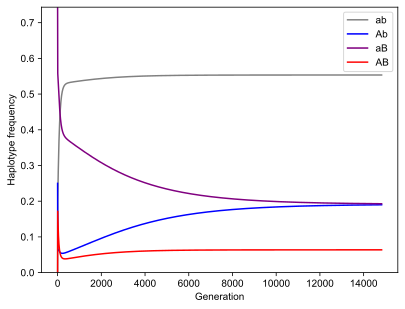

In [10]:
# Test deterministic and plot the result

# Define the starting value for testing
haplo_freq = np.array([0, 0.25, 0.75, 0])

# Define model parameters
epi_vec = np.array([0.019, 0.038, 0.076])     # epistasis, g1, g2, g4
overdom_vec = np.array([0.02, 0.02]) # overdominance (as alpha, beta)
mig_vec = np.array([0, 0])     # migration
rec = 0.5                      # recombination

# Define selection matrix for all 16 possible combinations of gametes (from mom and dad)
selection_mat = np.array([
    [1, 1 + overdom_vec[0], 1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0])],
    [1 + overdom_vec[0], 1, (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1])],
    [1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), 1, (1 + overdom_vec[1]) * (1 - epi_vec[1])],
    [(1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1]), (1 + overdom_vec[1]) * (1 - epi_vec[1]), 1 - epi_vec[2]]
])

max_gen = 30000

output = simulate_pop(haplo_freq, max_gen, selection_mat, mig_vec, rec)

# Show the last few lines of the data table
print(output[-1:])

# Plot the output
x_range = np.arange(len(output))
plt.plot(x_range, output[:, 0], label="ab", color="gray")
plt.plot(x_range, output[:, 1], label="Ab", color="blue")
plt.plot(x_range, output[:, 2], label="aB", color="purple")
plt.plot(x_range, output[:, 3], label="AB", color="red")
plt.ylim(0, np.max(output[:, 0] + output[:, 1]))
plt.xlabel("Generation")
plt.ylabel("Haplotype frequency")
plt.legend()
plt.show()

[[1.     1.02   1.02   1.0206]
 [1.02   1.     1.0206 0.9812]
 [1.02   1.0206 1.     0.9812]
 [1.0206 0.9812 0.9812 0.924 ]]
[0.8052 0.1948 0.     0.    ]


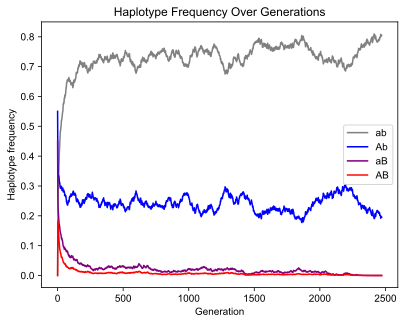

In [11]:
# Test stochastic
# Test parameters, no selection, no migration
sel_matrix = np.array([[1, 1, 1, 1], [1, 1, 1, 1], [1, 1, 1, 1], [1, 1, 1, 0]])  # Replace with actual selection matrix
mig_vec = np.array([0.0, 0.0])  # Replace with actual migration vector
popsize = 10000
rec_rate = 0.5  # Replace with actual recombination rate
t_max = 10000

# Run the simulation
initial_haplo_freq = np.array([0, 0.55, 0.45, 0])
output = simulate_pop(initial_haplo_freq, t_max, sel_matrix, mig_vec, rec_rate, popsize=popsize)
print(selection_mat)
# Display the last few lines of the output
print(output[-1])

# Plotting the result
x_range = np.arange(0, len(output))
plt.plot(x_range, output[:, 0], label='ab', color='gray')
plt.plot(x_range, output[:, 1], label='Ab', color='blue')
plt.plot(x_range, output[:, 2], label='aB', color='purple')
plt.plot(x_range, output[:, 3], label='AB', color='red')
plt.xlabel('Generation')
plt.ylabel('Haplotype frequency')
plt.title('Haplotype Frequency Over Generations')
plt.legend()
plt.show()

## 3 locus

First, setting up dynamics

### One generation

In [12]:
#With haplotype frequencies:
                     # abc,  Abc, aBc, ABc, abC,  AbC,  aBC,  ABC 
haplo_freq = np.array([0.00, 0.5, 0.0, 0.0, 0.00, 0.00, 0.5, 0.00])

# Define model parameters
epi_vec = np.array([0.021, 0.042, 0.084])     # epistasis, g1, g2, g4
overdom_vec = np.array([0.02, 0.02]) # overdominance (as alpha, beta)
mig_vec = np.array([0.01, 0.01])     # migration
rec = np.array([0.002,0.003])          # recombination between ab & bc
r_ab = rec[0]
r_bc = rec[1]


selection_mat = np.array([
    [1, 1 + overdom_vec[0], 1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0])],
    [1 + overdom_vec[0], 1, (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1])],
    [1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), 1, (1 + overdom_vec[1]) * (1 - epi_vec[1])],
    [(1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1]), (1 + overdom_vec[1]) * (1 - epi_vec[1]), 1 - epi_vec[2]]
])

sum(haplo_freq)

np.float64(1.0)

In [13]:
# repeat the selection matrix on rows and columns, to get the same selection coefficient with locus C
selection_mat_3 = np.tile(selection_mat,(2,2))
# selection_mat_3 = np.ones((8,8)) #Fully neutral

selection_mat_df = pd.DataFrame(data= selection_mat_3,
                                index = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"],
                                columns = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"])
selection_mat_df

,abc,Abc,aBc,ABc,abC,AbC,aBC,ABC
abc,1.000000,1.020000,1.020000,1.018552,1.000000,1.020000,1.020000,1.018552
Abc,1.020000,1.000000,1.018552,0.977160,1.020000,1.000000,1.018552,0.977160
aBc,1.020000,1.018552,1.000000,0.977160,1.020000,1.018552,1.000000,0.977160
ABc,1.018552,0.977160,0.977160,0.916000,1.018552,0.977160,0.977160,0.916000
abC,1.000000,1.020000,1.020000,1.018552,1.000000,1.020000,1.020000,1.018552
AbC,1.020000,1.000000,1.018552,0.977160,1.020000,1.000000,1.018552,0.977160
aBC,1.020000,1.018552,1.000000,0.977160,1.020000,1.018552,1.000000,0.977160
ABC,1.018552,0.977160,0.977160,0.916000,1.018552,0.977160,0.977160,0.916000


In [14]:
#Migration of Abc and aBC only 
# haplo_freq = haplo_freq * (1 - np.sum(mig_vec)) + np.array([0, mig_vec[0], 0, 0, 0, 0, mig_vec[1], 0])

In [15]:
# Random mating to create genotypes
geno_mat = np.outer(haplo_freq, haplo_freq)
# Selection step: multiply with selection table and renormalize by mean fitness
selection = selection_mat_3 * geno_mat
fit_mean = np.sum(selection)
geno_mat = selection / fit_mean

In [16]:
# Print genotype frequency matrix
print("Genotype Frequency Matrix after Selection:")
print("Genotype Frequency Matrix after Selection:")
print(geno_mat)
print("Sum of Genotype Frequencies:", np.sum(geno_mat))

Genotype Frequency Matrix after Selection:
Genotype Frequency Matrix after Selection:
[[0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.2477 0.     0.     0.     0.     0.2523 0.    ]
 [0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.2523 0.     0.     0.     0.     0.2477 0.    ]
 [0.     0.     0.     0.     0.     0.     0.     0.    ]]
Sum of Genotype Frequencies: 1.0


In [17]:
# Migration step. For Abc and aBC only 
geno_mat *= (1 - np.sum(mig_vec))
geno_mat[1, 1] += mig_vec[0]
geno_mat[6, 6] += mig_vec[1]

In [18]:
# Setting up all recombination terms
rec_vec = np.zeros(8)
## abc
# Loses
rec_vec[0] = (-r_bc*(geno_mat[0,6] + geno_mat[6,0])/2         # abc/aBC -> abC + aBc
- r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
- r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
- r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc -> Abc + aBc
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2 # abc/ABC -> aBc + AbC lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
+ r_ab*(1-r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC -> ABC + abc
+ r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # abC/aBc -> abc + aBC
+ r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # abC/ABc -> abc + ABC
+ r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
+ r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
+ r_ab*r_bc*(geno_mat[2,5] + geno_mat[5,2])/2)                # aBc/AbC -> abc + ABC


## Abc
# Loses
rec_vec[1] = (-r_bc*(geno_mat[1,7] + geno_mat[7,1])/2         # Abc/ABC -> AbC + ABc
- r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
- r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
- r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2 # Abc/aBC lose when rec a, c and b
# Gains 
+ r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc
+ r_ab*(1-r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC 
+ r_bc*(geno_mat[5,3] + geno_mat[3,5])/2                      # AbC/ABc
+ r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # AbC/aBc
+ r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
+ r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
+ r_ab*r_bc*(geno_mat[3,4] + geno_mat[4,3])/2)                # ABc/abC


## aBc
# Loses
rec_vec[2] = (-r_bc*(geno_mat[2,4] + geno_mat[4,2])/2         # aBc/abC
- r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
- r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
- r_ab*(geno_mat[2,1] + geno_mat[1,2])/2                      # aBc/Abc
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2 # aBc/AbC lose when rec a, c and b
# Gains 
+ r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
+ r_ab*(1-r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC 
+ r_bc*(geno_mat[6,0] + geno_mat[0,6])/2                      # aBC/abc
+ r_bc*(1-r_ab)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
+ r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
+ r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
+ r_ab*r_bc*(geno_mat[0,7] + geno_mat[7,0])/2)                # abc/ABC

## ABc
# Loses
rec_vec[3] = (-r_bc*(geno_mat[3,5] + geno_mat[5,3])/2         # ABc/AbC
- r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
- r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
- r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2 # ABc/abC lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # aBc/Abc
+ r_ab*(1-r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
+ r_bc*(geno_mat[7,1] + geno_mat[1,7])/2                      # ABC/Abc
+ r_bc*(1-r_ab)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
+ r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
+ r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
+ r_ab*r_bc*(geno_mat[1,6] + geno_mat[6,1])/2)                # Abc/aBC

## abC
# Loses
rec_vec[4] = (-r_bc*(geno_mat[4,2] + geno_mat[2,4])/2         # abC/aBc
- r_bc*(1-r_ab)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
- r_ab*(1-r_bc)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
- r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2 # abC/ABc lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC
+ r_ab*(1-r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2             # AbC/aBc
+ r_bc*(geno_mat[0,6] + geno_mat[6,0])/2                      # abc/aBC
+ r_bc*(1-r_ab)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC
+ r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
+ r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
+ r_ab*r_bc*(geno_mat[6,1] + geno_mat[1,6])/2)                # aBC/Abc

## AbC
# Loses
rec_vec[5] = (-r_bc*(geno_mat[5,3] + geno_mat[3,5])/2         # AbC/ABc switch b and c
- r_bc*(1-r_ab)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc switch a and c
- r_ab*(1-r_bc)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc "
- r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC Switch a and b
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2 # AbC/aBc lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
+ r_ab*(1-r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2             # abC/ABc
+ r_bc*(geno_mat[1,7] + geno_mat[7,1])/2                      # Abc/ABC
+ r_bc*(1-r_ab)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC
+ r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
+ r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
+ r_ab*r_bc*(geno_mat[7,0] + geno_mat[0,7])/2)                # ABC/abc


## aBC
# Loses
rec_vec[6] = (-r_bc*(geno_mat[6,0] + geno_mat[0,6])/2         # aBC/abc switch b and c
- r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc switch a and c
- r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc "
- r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC Switch a and b
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2 # aBC/Abc lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC
+ r_ab*(1-r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
+ r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # aBc/abC
+ r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
+ r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
+ r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
+ r_ab*r_bc*(geno_mat[4,3] + geno_mat[3,4])/2)                # abC/ABc


## ABC
# Loses
rec_vec[7] = (-r_bc*(geno_mat[7,1] + geno_mat[1,7])/2         # ABC/Abc switch b and c
- r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc switch a and c
- r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc "
- r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC Switch a and b
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2 # ABC/abc lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC
+ r_ab*(1-r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
+ r_bc*(geno_mat[3,5] + geno_mat[5,3])/2                      # ABc/AbC
+ r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC
+ r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
+ r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
+ r_ab*r_bc*(geno_mat[5,2] + geno_mat[2,5])/2)                # AbC/aBc


In [19]:
# Return from genotype level to gametes/haplotypes with recombination
haplo_freq = np.array([
    np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) + rec_vec[0],
    np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) + rec_vec[1],
    np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) + rec_vec[2],
    np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) + rec_vec[3],
    np.sum(geno_mat[4, :] / 2 + geno_mat[:, 4] / 2) + rec_vec[4],
    np.sum(geno_mat[5, :] / 2 + geno_mat[:, 5] / 2) + rec_vec[5],
    np.sum(geno_mat[6, :] / 2 + geno_mat[:, 6] / 2) + rec_vec[6],
    np.sum(geno_mat[7, :] / 2 + geno_mat[:, 7] / 2) + rec_vec[7],
])

# Print the haplotype frequencies after recombination
print("Haplotype Frequencies after Recombination:")
print(haplo_freq)
print("Sum of Haplotype Frequencies:", np.sum(haplo_freq))


Haplotype Frequencies after Recombination:
[4.9302e-04 4.9877e-01 7.4027e-04 1.4835e-06 1.4835e-06 7.4027e-04
 4.9877e-01 4.9302e-04]
Sum of Haplotype Frequencies: 1.0


### Simulation functions, one generation

In [20]:
def get_heterozygosity(frequency):
    return 1 - (((frequency)**2) + ((1-frequency)**2))

In [21]:
def simulate_one_gen_3(haplo_freq, selection_mat, mig_vec, rec):
    # Life cycle: 1. Parental gametes to newborn genotypes w random mating; 2. Selection, 3. Migration, 4. Recombination

    geno_mat = np.outer(haplo_freq, haplo_freq)

    # Determine genotype frequencies assuming random mating for all 16 genotypes
    geno_mat = np.outer(haplo_freq, haplo_freq)

    # Selection step
    selection = selection_mat * geno_mat
    fit_mean = np.sum(selection)
    geno_mat = selection / fit_mean

    # Migration step (if adult genotypes arrive after selection) -> Should the negative term apply to all?
    geno_mat *= (1 - np.sum(mig_vec))
    geno_mat[1, 1] += mig_vec[0]
    geno_mat[6, 6] += mig_vec[1]


    # Recombination terms
    rec_vec = np.zeros(8)
    r_ab = rec[0]
    r_bc = rec[1]

    ## abc
    # Loses
    rec_vec[0] = (-r_bc*(geno_mat[0,6] + geno_mat[6,0])/2         # abc/aBC -> abC + aBc
    - r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
    - r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
    - r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc -> Abc + aBc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2 # abc/ABC -> aBc + AbC lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
    + r_ab*(1-r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC -> ABC + abc
    + r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # abC/aBc -> abc + aBC
    + r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # abC/ABc -> abc + ABC
    + r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
    + r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
    + r_ab*r_bc*(geno_mat[2,5] + geno_mat[5,2])/2)                # aBc/AbC -> abc + ABC
    
    
    ## Abc
    # Loses
    rec_vec[1] = (-r_bc*(geno_mat[1,7] + geno_mat[7,1])/2         # Abc/ABC -> AbC + ABc
    - r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
    - r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
    - r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2 # Abc/aBC lose when rec a, c and b
    # Gains 
    + r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc
    + r_ab*(1-r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC 
    + r_bc*(geno_mat[5,3] + geno_mat[3,5])/2                      # AbC/ABc
    + r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # AbC/aBc
    + r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*r_bc*(geno_mat[3,4] + geno_mat[4,3])/2)                # ABc/abC
    
    
    ## aBc
    # Loses
    rec_vec[2] = (-r_bc*(geno_mat[2,4] + geno_mat[4,2])/2         # aBc/abC
    - r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    - r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    - r_ab*(geno_mat[2,1] + geno_mat[1,2])/2                      # aBc/Abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2 # aBc/AbC lose when rec a, c and b
    # Gains 
    + r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
    + r_ab*(1-r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC 
    + r_bc*(geno_mat[6,0] + geno_mat[0,6])/2                      # aBC/abc
    + r_bc*(1-r_ab)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
    + r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
    + r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
    + r_ab*r_bc*(geno_mat[0,7] + geno_mat[7,0])/2)                # abc/ABC
    
    ## ABc
    # Loses
    rec_vec[3] = (-r_bc*(geno_mat[3,5] + geno_mat[5,3])/2         # ABc/AbC
    - r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    - r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    - r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2 # ABc/abC lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # aBc/Abc
    + r_ab*(1-r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
    + r_bc*(geno_mat[7,1] + geno_mat[1,7])/2                      # ABC/Abc
    + r_bc*(1-r_ab)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
    + r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
    + r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
    + r_ab*r_bc*(geno_mat[1,6] + geno_mat[6,1])/2)                # Abc/aBC
    
    ## abC
    # Loses
    rec_vec[4] = (-r_bc*(geno_mat[4,2] + geno_mat[2,4])/2         # abC/aBc
    - r_bc*(1-r_ab)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
    - r_ab*(1-r_bc)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
    - r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2 # abC/ABc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC
    + r_ab*(1-r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2             # AbC/aBc
    + r_bc*(geno_mat[0,6] + geno_mat[6,0])/2                      # abc/aBC
    + r_bc*(1-r_ab)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC
    + r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*r_bc*(geno_mat[6,1] + geno_mat[1,6])/2)                # aBC/Abc
    
    ## AbC
    # Loses
    rec_vec[5] = (-r_bc*(geno_mat[5,3] + geno_mat[3,5])/2         # AbC/ABc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc "
    - r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2 # AbC/aBc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
    + r_ab*(1-r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2             # abC/ABc
    + r_bc*(geno_mat[1,7] + geno_mat[7,1])/2                      # Abc/ABC
    + r_bc*(1-r_ab)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC
    + r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
    + r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
    + r_ab*r_bc*(geno_mat[7,0] + geno_mat[0,7])/2)                # ABC/abc
    
    
    ## aBC
    # Loses
    rec_vec[6] = (-r_bc*(geno_mat[6,0] + geno_mat[0,6])/2         # aBC/abc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc "
    - r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2 # aBC/Abc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC
    + r_ab*(1-r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
    + r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # aBc/abC
    + r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
    + r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    + r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    + r_ab*r_bc*(geno_mat[4,3] + geno_mat[3,4])/2)                # abC/ABc
    
    
    ## ABC
    # Loses
    rec_vec[7] = (-r_bc*(geno_mat[7,1] + geno_mat[1,7])/2         # ABC/Abc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc "
    - r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2 # ABC/abc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC
    + r_ab*(1-r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
    + r_bc*(geno_mat[3,5] + geno_mat[5,3])/2                      # ABc/AbC
    + r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC
    + r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    + r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    + r_ab*r_bc*(geno_mat[5,2] + geno_mat[2,5])/2)                # AbC/aBc

    
    # Return to gametes/haplotypes with recombination
    haplo_freq = np.array([
        np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) + rec_vec[0],
        np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) + rec_vec[1],
        np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) + rec_vec[2],
        np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) + rec_vec[3],
        np.sum(geno_mat[4, :] / 2 + geno_mat[:, 4] / 2) + rec_vec[4],
        np.sum(geno_mat[5, :] / 2 + geno_mat[:, 5] / 2) + rec_vec[5],
        np.sum(geno_mat[6, :] / 2 + geno_mat[:, 6] / 2) + rec_vec[6],
        np.sum(geno_mat[7, :] / 2 + geno_mat[:, 7] / 2) + rec_vec[7]
    ])

    return haplo_freq

# Test the function
print(simulate_one_gen_3(np.array([0.07, 0.05, 0.12, 0.51, 0.06, 0.04, 0.13, 0.02]), selection_mat_3, mig_vec, rec))


[0.0717 0.0602 0.1203 0.4873 0.0613 0.0401 0.1395 0.0196]


In [22]:
#Stochastic simulation
def simulate_one_gen_stoch_3(haplo_freq, sel_matrix, mig_vec, popsize, rec_rate):
    # Convert migration vector from rate to absolute number of migrants
    migno_vec = mig_vec * popsize

    # Determine genotype frequencies assuming random mating
    geno_mat = np.outer(haplo_freq, haplo_freq) # Get all 16 genotype frequencies

    # Selection step
    selection = sel_matrix * geno_mat 
    fit_mean = np.sum(selection)
    geno_mat = selection / fit_mean

    # Determine number of migrants that arrive this generation
    migrants = [poisson.rvs(migno_vec[0]), poisson.rvs(migno_vec[1])]

    # Determine population composition after selection (leaving space for migrants)
    flat_genfreq = geno_mat.flatten()
    
    popsize_matrix = np.reshape(np.random.multinomial(popsize - sum(migrants), flat_genfreq), (8, 8))
        
    # Introduce migrant genotypes
    popsize_matrix[1, 1] += migrants[0]
    popsize_matrix[6, 6] += migrants[1]

    # Return to genotype frequencies
    geno_mat = popsize_matrix / np.sum(popsize_matrix)

    # Recombination terms
    # Recombination terms
    rec_vec = np.zeros(8)
    r_ab = rec[0]
    r_bc = rec[1]

    ## abc
    # Loses
    rec_vec[0] = (-r_bc*(geno_mat[0,6] + geno_mat[6,0])/2         # abc/aBC -> abC + aBc
    - r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
    - r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
    - r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc -> Abc + aBc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2 # abc/ABC -> aBc + AbC lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
    + r_ab*(1-r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC -> ABC + abc
    + r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # abC/aBc -> abc + aBC
    + r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # abC/ABc -> abc + ABC
    + r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
    + r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
    + r_ab*r_bc*(geno_mat[2,5] + geno_mat[5,2])/2)                # aBc/AbC -> abc + ABC
    
    
    ## Abc
    # Loses
    rec_vec[1] = (-r_bc*(geno_mat[1,7] + geno_mat[7,1])/2         # Abc/ABC -> AbC + ABc
    - r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
    - r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
    - r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2 # Abc/aBC lose when rec a, c and b
    # Gains 
    + r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc
    + r_ab*(1-r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC 
    + r_bc*(geno_mat[5,3] + geno_mat[3,5])/2                      # AbC/ABc
    + r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # AbC/aBc
    + r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*r_bc*(geno_mat[3,4] + geno_mat[4,3])/2)                # ABc/abC
    
    
    ## aBc
    # Loses
    rec_vec[2] = (-r_bc*(geno_mat[2,4] + geno_mat[4,2])/2         # aBc/abC
    - r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    - r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    - r_ab*(geno_mat[2,1] + geno_mat[1,2])/2                      # aBc/Abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2 # aBc/AbC lose when rec a, c and b
    # Gains 
    + r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
    + r_ab*(1-r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC 
    + r_bc*(geno_mat[6,0] + geno_mat[0,6])/2                      # aBC/abc
    + r_bc*(1-r_ab)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
    + r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
    + r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
    + r_ab*r_bc*(geno_mat[0,7] + geno_mat[7,0])/2)                # abc/ABC
    
    ## ABc
    # Loses
    rec_vec[3] = (-r_bc*(geno_mat[3,5] + geno_mat[5,3])/2         # ABc/AbC
    - r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    - r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    - r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2 # ABc/abC lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # aBc/Abc
    + r_ab*(1-r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
    + r_bc*(geno_mat[7,1] + geno_mat[1,7])/2                      # ABC/Abc
    + r_bc*(1-r_ab)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
    + r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
    + r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
    + r_ab*r_bc*(geno_mat[1,6] + geno_mat[6,1])/2)                # Abc/aBC
    
    ## abC
    # Loses
    rec_vec[4] = (-r_bc*(geno_mat[4,2] + geno_mat[2,4])/2         # abC/aBc
    - r_bc*(1-r_ab)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
    - r_ab*(1-r_bc)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
    - r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2 # abC/ABc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC
    + r_ab*(1-r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2             # AbC/aBc
    + r_bc*(geno_mat[0,6] + geno_mat[6,0])/2                      # abc/aBC
    + r_bc*(1-r_ab)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC
    + r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*r_bc*(geno_mat[6,1] + geno_mat[1,6])/2)                # aBC/Abc
    
    ## AbC
    # Loses
    rec_vec[5] = (-r_bc*(geno_mat[5,3] + geno_mat[3,5])/2         # AbC/ABc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc "
    - r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2 # AbC/aBc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
    + r_ab*(1-r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2             # abC/ABc
    + r_bc*(geno_mat[1,7] + geno_mat[7,1])/2                      # Abc/ABC
    + r_bc*(1-r_ab)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC
    + r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
    + r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
    + r_ab*r_bc*(geno_mat[7,0] + geno_mat[0,7])/2)                # ABC/abc
    
    
    ## aBC
    # Loses
    rec_vec[6] = (-r_bc*(geno_mat[6,0] + geno_mat[0,6])/2         # aBC/abc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc "
    - r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2 # aBC/Abc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC
    + r_ab*(1-r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
    + r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # aBc/abC
    + r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
    + r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    + r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    + r_ab*r_bc*(geno_mat[4,3] + geno_mat[3,4])/2)                # abC/ABc
    
    
    ## ABC
    # Loses
    rec_vec[7] = (-r_bc*(geno_mat[7,1] + geno_mat[1,7])/2         # ABC/Abc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc "
    - r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2 # ABC/abc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC
    + r_ab*(1-r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
    + r_bc*(geno_mat[3,5] + geno_mat[5,3])/2                      # ABc/AbC
    + r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC
    + r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    + r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    + r_ab*r_bc*(geno_mat[5,2] + geno_mat[2,5])/2)                # AbC/aBc

    # Return to gametes/haplotypes with recombination
    haplo_freq = np.array([
        np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) + rec_vec[0],
        np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) + rec_vec[1],
        np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) + rec_vec[2],
        np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) + rec_vec[3],
        np.sum(geno_mat[4, :] / 2 + geno_mat[:, 4] / 2) + rec_vec[4],
        np.sum(geno_mat[5, :] / 2 + geno_mat[:, 5] / 2) + rec_vec[5],
        np.sum(geno_mat[6, :] / 2 + geno_mat[:, 6] / 2) + rec_vec[6],
        np.sum(geno_mat[7, :] / 2 + geno_mat[:, 7] / 2) + rec_vec[7]
    ])

    return haplo_freq


max_gen = 25000
haplotype_freq = np.array([0.07, 0.05, 0.22, 0.41, 0.06, 0.04, 0.13, 0.02])
popsize=10000
print(simulate_one_gen_stoch_3(haplotype_freq, selection_mat_3, mig_vec, popsize, rec))


[0.0703 0.0598 0.2205 0.3927 0.0594 0.0393 0.139  0.0191]


In [23]:
# Simulate the entire population
def simulate_pop_3(haplo_freq0, t_max, sel_matrix, mig_vec, rec_rate, popsize=0):
    # Create the matrix to store results
    pop_vector = [haplo_freq0]
    pop_new = haplo_freq0

    # Run the simulation until generation t_max
    for i in range(1, t_max + 1):
        if popsize==0: # If the parameter is 0, do the deterministic case
            # Update the population one generation later
            pop_new = simulate_one_gen_3(pop_new, sel_matrix, mig_vec, rec_rate)
        else:
            pop_new = simulate_one_gen_stoch_3(pop_new, sel_matrix, mig_vec, popsize, rec_rate)
        pop_vector.append(pop_new)
        # Stop simulation early if allele frequency change is very small
        if np.sum(np.abs(pop_vector[i] - pop_vector[i - 1])) < 1e-12:
            break

    # Convert the result list to a numpy array
    pop_vector = np.array(pop_vector)
    
    # Define row and column names (as labels in the output)
    return pop_vector


In [24]:
# Function to get the selection matrix given overdominance coefficients
def get_selection_mat(overdom_vec, epi_vec, neutb=False):
    alpha = overdom_vec[0]
    beta = overdom_vec[1]
    gamma1 = epi_vec[0]
    gamma2 = epi_vec[1]
    gamma3 = epi_vec[1]
    gamma4 = epi_vec[2]
    
    selection_mat = np.array([
        [1, 1 + overdom_vec[0], 1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0])],
        [1 + overdom_vec[0], 1, (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1])],
        [1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), 1, (1 + overdom_vec[1]) * (1 - epi_vec[1])],
        [(1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1]), (1 + overdom_vec[1]) * (1 - epi_vec[1]), 1 - epi_vec[2]]
    ])

    selection_mat_3 = np.tile(selection_mat,(2,2)) # The selection matrix is a repetition of the AB matrix 
    
    if neutb: # Neutral B has a different selection matrix
        selection_mat_3 = np.array([
            [1, 1+alpha, 1, 1+alpha, (1+beta), (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1)],
            [1+alpha, 1, 1+alpha, 1, (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2)],
            [1, 1+alpha, 1, 1+alpha, (1+beta), (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1)],
            [1+alpha, 1, 1+alpha, 1, (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2)],
            [1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1, (1+alpha)*(1-gamma2), 1, (1+alpha)*(1-gamma2)],
            [(1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1-gamma2), 1-gamma4, (1+alpha)*(1-gamma2), 1-gamma4],
            [1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1, (1+alpha)*(1-gamma2), 1, (1+alpha)*(1-gamma2)],
            [(1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1-gamma2), 1-gamma4, (1+alpha)*(1-gamma2), 1-gamma4]    
        ]) 
    return(selection_mat_3)


In [25]:
# Convert haplotypes to alleles
def get_alleles(haplotypes):
    pA = haplotypes[[1,3,5,7]]
    pB = haplotypes[[2,3,6,7]]
    pC = haplotypes[[4,5,6,7]]
    return [sum(pA),sum(pB),sum(pC)]

In [26]:
# Function to convert between recombinaiton rate and distance
def rec_to_distance(r):
    return (-0.5*np.log(1-2*r))

def distance_to_rec(d):
    return (0.5*(1-np.exp((-2*d))))

In [27]:
def simulate_populations(haplo_freq, 
                         max_gen,
                         selection_mat,
                         mig,      
                         recombination_list,
                         neutb=False,
                         outtype='alleles',
                         **kwargs, #rmin=-4,rmax=0,steps=20,steps=20, npoints=25
                        ):


    defaultkwargs = {'rmin':-5, 'rmax':0, 'steps':25, 'npoints':25}# Defaulting kwargs
    kwargs = {**kwargs, **defaultkwargs} #Unpack
    out = []
    outhaplo = []
    outdata = []
    alleles = ['A', 'B', 'C']

    if neutb: # Neutral B (A-N-B)
        everyn = int(100/kwargs['npoints'])
        for totr in recombination_list:
            for rab in range(0,101,everyn):
                freqs = []
                #for i in np.linspace(-4,0,20):
                r_ab = totr*rab/100
                r_bc = totr-(totr*rab/100)
                output = simulate_pop_3(haplo_freq, max_gen, selection_mat, [0,0], [r_ab, r_bc])
                t_max = len(output)
                freqs.append([t_max, r_ab, r_bc, totr, get_alleles(output[-1])])
                out.append(freqs)
                outhaplo.append([t_max, r_ab, r_bc])
                outhaplo[-1].extend(output[-1])
    
        #Extract allele data and create df
        haplodf = pd.DataFrame(outhaplo, columns=['tmax','r_ab', 'r_bc', 'anb', 'Anb', 'aNb', 'ANb', 'anB', 'AnB', 'aNB', 'ANB'])
        
        for feature_idx, feature in enumerate(out):
            for t_max, rab, rbc, totr, y_values in feature:
                for allele, y in zip(alleles, y_values):
                    outdata.append({'t_max': t_max,'r_ab': totr, 'r_bc': rbc, 'allele': allele, 'freq': y, 'pos': rab/totr, 'r_an':rab})


    else: # Neutral C (A-B-N)
        for rab in recombination_list:
            freqs = []
            for i in np.linspace(kwargs['rmin'],kwargs['rmax'],kwargs['steps']):
                output = simulate_pop_3(haplo_freq, max_gen, selection_mat, mig, [rab, 0.5*10**(i)])
                t_max = len(output)
                freqs.append([t_max, 0.5*10**(i), get_alleles(output[-1])])
                outhaplo.append([t_max, rab, 0.5*10**(i)])
                outhaplo[-1].extend(output[-1])
            out.append(freqs)
        haplodf = pd.DataFrame(outhaplo, columns=['tmax','r_ab', 'r_bn', 'abn',  'Abn', 'aBn', 'ABn', 'abN', 'AbN', 'aBN', 'ABN'])

    
        for feature_idx, feature in enumerate(out):
            for t_max, x_value, y_values in feature:
                for allele, y in zip(alleles, y_values):
                    outdata.append({'t_max': t_max, 'r_ab': recombination_list[feature_idx], 'r_bc': x_value, 'allele': allele, 'freq': y })


    # Create a DataFrame
    df = pd.DataFrame(outdata)
    df['het'] = 1 - (((df.freq)**2) + ((1-df.freq)**2)) # Calculate heterozygosity
    if neutb:
        df.loc[:, 'allele'] = df['allele'].replace({'B': 'N'})
        df.loc[:, 'allele'] = df['allele'].replace({'C': 'B'})
    else:
        df.loc[:, 'allele'] = df['allele'].replace({'C': 'N'})       # Replace 
    df['r_ab'] = [f"{i:.0e}" for i in df['r_ab']]        # Change to scientific notation      

    return df, haplodf
    
    

#### Neutral B

If we want B to be neutral, only the fitness matrix has to be different.  

In [29]:
# For reference, 3 loci with b neutral
selection_mat_neutbte = np.array([
    ["1", "1+A", "1", "1+A", "(1+B)", "(1+A)*(1+B)*(1-G1)", "1+B", "(1+A)*(1+B)*(1-G1)"],
    ["1+A", "1", "1+A", "1", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)"],
    ["1", "1+A", "1", "1+A", "(1+B)", "(1+A)*(1+B)*(1-G1)", "1+B", "(1+A)*(1+B)*(1-G1)"],
    ["1+A", "1", "1+A", "1", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)"],
    ["1+B", "(1+A)*(1+B)*(1-G1)", "1+B", "(1+A)*(1+B)*(1-G1)", "1", "(1+A)*(1-G2)", "1", "(1+A)*(1-G2)"],
    ["(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1-G2)", "1-G4", "(1+A)*(1-G2)", "1-G4"],
    ["1+B", "(1+A)*(1+B)*(1-G1)", "1+B", "(1+A)*(1+B)*(1-G1)", "1", "(1+A)*(1-G2)", "1", "(1+A)*(1-G2)"],
    ["(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1-G2)", "1-G4", "(1+A)*(1-G2)", "1-G4"]    
])

selection_mat_df = pd.DataFrame(data= selection_mat_neutbte,
                                index = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"],
                                columns = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"])
selection_mat_df

,abc,Abc,aBc,ABc,abC,AbC,aBC,ABC
abc,1,1+A,1,1+A,(1+B),(1+A)*(1+B)*(1-G1),1+B,(1+A)*(1+B)*(1-G1)
Abc,1+A,1,1+A,1,(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1+B)*(1-G1),(1+B)*(1-G2)
aBc,1,1+A,1,1+A,(1+B),(1+A)*(1+B)*(1-G1),1+B,(1+A)*(1+B)*(1-G1)
ABc,1+A,1,1+A,1,(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1+B)*(1-G1),(1+B)*(1-G2)
abC,1+B,(1+A)*(1+B)*(1-G1),1+B,(1+A)*(1+B)*(1-G1),1,(1+A)*(1-G2),1,(1+A)*(1-G2)
AbC,(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1-G2),1-G4,(1+A)*(1-G2),1-G4
aBC,1+B,(1+A)*(1+B)*(1-G1),1+B,(1+A)*(1+B)*(1-G1),1,(1+A)*(1-G2),1,(1+A)*(1-G2)
ABC,(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1-G2),1-G4,(1+A)*(1-G2),1-G4


In [30]:
alpha = overdom_vec[0]
beta = overdom_vec[1]
gamma1 = epi_vec[0]
gamma2 = epi_vec[1]
gamma4 = epi_vec[2]

selection_mat_neutb = np.array([
    [1, 1+alpha, 1, 1+alpha, (1+beta), (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1)],
    [1+alpha, 1, 1+alpha, 1, (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2)],
    [1, 1+alpha, 1, 1+alpha, (1+beta), (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1)],
    [1+alpha, 1, 1+alpha, 1, (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2)],
    [1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1, (1+alpha)*(1-gamma2), 1, (1+alpha)*(1-gamma2)],
    [(1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1-gamma2), 1-gamma4, (1+alpha)*(1-gamma2), 1-gamma4],
    [1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1, (1+alpha)*(1-gamma2), 1, (1+alpha)*(1-gamma2)],
    [(1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1-gamma2), 1-gamma4, (1+alpha)*(1-gamma2), 1-gamma4]    
])

selection_mat_df = pd.DataFrame(data= selection_mat_neutb,
                                index = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"],
                                columns = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"])
#selection_mat_df

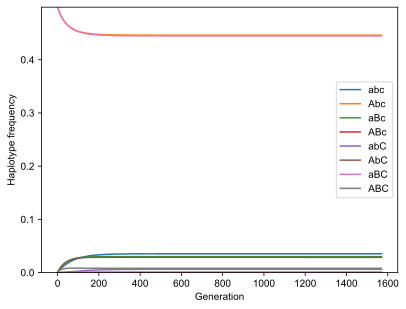

[0.0354 0.4461 0.03   0.0008 0.0062 0.0287 0.4448 0.0081]


In [31]:
# Test the function and plot the result
max_gen = 25000

output = simulate_pop_3(haplo_freq, max_gen, selection_mat_3, mig_vec, rec)

# Show the last few lines of the data table
#print(output[-5:])


# Plot the output
x_range = np.arange(len(output))
haplotypes = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"]

for i in range(len(haplotypes)):
    plt.plot(x_range, output[:, i], label=haplotypes[i])
plt.ylim(0, np.max(output))
plt.xlabel("Generation")
plt.ylabel("Haplotype frequency")
plt.legend()
plt.show()
print(output[-1])

### Functions for plotting

In [32]:
def plot_rec_freqs(haplo_freq, max_gen, selection_mat, mig, rab=0.00001):
    freqs = []
    for i in np.linspace(-4,0.5,20):
        output = simulate_pop_3(haplo_freq, max_gen, selection_mat, mig, [rab, 0.5*10**(i)])
        freqs.append([0.5*10**(i), get_alleles(output[-1])])
        
    plt.plot([i[0] for i in freqs], [i[1] for i in freqs], '--s', label=["A","B","C"], alpha=0.5)
    plt.ylim(0, 1)
    plt.colormaps
    plt.xscale('log')
    plt.xlabel("r_bc")
    plt.ylabel("Allele frequency")
    plt.legend()
    plt.show()
    return(freqs[-1][1])
    

In [33]:
def plot_dyn_haplo(haplo_freq, max_gen, selection_mat, mig, r, title=""):
                          # abc,  Abc, aBc, ABc, abC,  AbC,  aBC,  ABC 
    output = simulate_pop_3(haplo_freq, max_gen, selection_mat, mig, r)
    
    # Show the last few lines of the data table
    #print(output[-5:])
    
    
    # Plot the output
    x_range = np.arange(len(output))
    haplotypes = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"]
    
    for i in range(len(haplotypes)):
        plt.plot(x_range, output[:, i], label=haplotypes[i])
        
    plt.ylim(0, np.max(output)+0.05)
    plt.xlabel("Generation")
    plt.ylabel("Haplotype frequency")
    plt.title(title)
    plt.legend()
    plt.show()
    return(output[-1])

In [34]:
def plot_dyn_freqs(haplo_freq, 
                   max_gen, 
                   selection_mat, 
                   mig, 
                   r, 
                   title="", 
                   neut="C", 
                   palette = {'A':'#5C43AF','B':'#FE842F', 'N':'#194122', 'A,B':'#FE842F'},
                   exclude=[],
                   **kwargs):
                          # abc,  Abc, aBc, ABc, abC,  AbC,  aBC,  ABC 
    output = simulate_pop_3(haplo_freq, max_gen, selection_mat, mig, r)
    
    # Show the last few lines of the data table
    #print(output[-5:])
    
    
    # Plot the output
    x_range = np.arange(len(output))
    allele_freq = np.array(list(map(get_alleles, output)))
    alleles = ["A", "B", "C"]
    alleles[alleles.index(neut)] = "N"
    
    df_alleles = pd.DataFrame(allele_freq, columns=alleles)
    df_alleles['t'] = df_alleles.index
    df_alleles = df_alleles.melt(id_vars='t', value_vars=alleles, 
                        var_name='allele', value_name='freq')

    if exclude:
        df_alleles = df_alleles[~df_alleles['allele'].isin(exclude)]
    
    palette = {'A':'#5C43AF','B':'#FE842F', 'N':'#194122', 'A,B':'#FE842F'}

    fig, ax = plt.subplots()
    figfreqs = sns.lineplot(data=df_alleles, x='t', y='freq', hue='allele',
            palette=palette, alpha=0.8)
    
    plt.legend(title='Allele')
    plt.xlabel("Generation")
    plt.ylabel("Allele frequency")
    sns.despine()
    plt.title(title)
    plt.legend(title="Allele", bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, frameon=False)
    plt.show()
    if "filename" in kwargs.keys():
        fig.savefig(kwargs["filename"])
    return(get_alleles(output[-1]))

In [35]:
def plot_heterozygosity_dist(haplo_freq, 
                             max_gen, 
                             selection_mat, 
                             mig, 
                             recombination_list, 
                             palette = {'A':'#5C43AF','B':'#FE842F', 'N':'#194122', 'A,B':'#FE842F'},
                             yaxis ='het',
                             allelelist = ['B', 'N'],
                             **kwargs):
    # Plotting different r between A and B
    out = []
    #for rab in [0,0.0001,0.001,0.01,0.1,0.5]:
    for rab in recombination_list:
        freqs = []
        for i in np.linspace(-4,0,20):
            output = simulate_pop_3(haplo_freq, max_gen, selection_mat, mig, [rab, 0.5*10**(i)])
            freqs.append([0.5*10**(i), get_alleles(output[-1])])
        out.append(freqs)
    
    data = []
    alleles = ['A', 'B', 'C']

    for feature_idx, feature in enumerate(out):
        for x_value, y_values in feature:
            for allele, y in zip(alleles, y_values):
                data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': recombination_list[feature_idx]})


    # Create a DataFrame
    df = pd.DataFrame(data)
    df['het'] = 1 - (((df.freq)**2) + ((1-df.freq)**2)) # Calculate heterozygosity
    df['allele'] = df['allele'].replace({'C':'N'})       # Replace 
    df = df[df['allele'].isin(allelelist)]
    if ('A' not in allelelist and yaxis=='het'): # Change the label of B to A,B for clarity
        print(allelelist)
        df['allele'] = df['allele'].replace({'B':'A,B'})

    df['r_ab'] = [f"{i:.0e}" for i in df['r_ab']]


    ## Get custom height and width if provided
    height = kwargs.get("height", 6)
    width = kwargs.get("width", height * 1.3)  # default aspect ratio if width not provided
    aspect = width / height
    
    figfreqs = sns.relplot(data=df, x='r', y=yaxis, hue='allele',
        style='r_ab', kind="line", markers=True,
        palette=palette, alpha=0.8,
        height=height, aspect=aspect)

    legend = figfreqs._legend  
    if legend:
        for text in legend.get_texts():
            if text.get_text() == "allele":
                if yaxis=='het':
                    text.set_text("Locus")  # Change label
                elif yaxis=='freq':
                    text.set_text("Allele")  
            elif text.get_text() == "r_ab":
                text.set_text(r"$r_{ab}$")             
        
        # Move the legend to the upper right
        legend.set_bbox_to_anchor((0.8, 0.78))  # Position it in the upper right corner
        legend.set_frame_on(True)  


    for ax in figfreqs.axes.flat:
        for line in ax.lines:
            line.set_markersize(8) 
   
    plt.xlabel(r"$r_{bn}$")
    if yaxis=='het':
        plt.ylabel("Heterozygosity")
    elif yaxis=='freq':
        plt.ylabel("Frequency")

    # Get X-axis limits
    ax = figfreqs.ax
    xmin, xmax = ax.get_xlim()

    # Set log scale on x-axis
    ax.set_xscale('log')

    # ax.axhline(0.5, ls=':', linewidth=1, color='red', alpha = 0.5) # Red line at 0.5, for testing

    ax.text(0.01, -0.02, "AB", ha='center', va='top', fontsize=10, transform=ax.transAxes)
    ax.text(0.98, -0.02, "→N", ha='center', va='top', fontsize=10, transform=ax.transAxes)
    
    #ax = plt.subplot(111)
    #plt.xscale('log')
    #plt.ylim(0, np.max(df[yaxis])+0.05)
    plt.ylim(0, 1)
    if "title" in kwargs.keys():
        plt.title(kwargs["title"])
      
    plt.show()

    if "filename" in kwargs.keys():
        figfreqs.savefig(kwargs["filename"])
    #return df
    #plt.savefig('fighet_ppt.svg')-

In [36]:
## Test
##
# haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
# overdom = [0.03,0.03]
# epi_vec = [0.03,0.06,0.06,0.12]
# rab = [1e-6,1e-1]
# df = plot_heterozygosity_dist(haplo_freq, 
#                          1000, 
#                          get_selection_mat(overdom, epi_vec), 
#                          mig_vec,
#                          rab,
#                          title = 'Heterozygosity of C at equilibrium as a function of $r_{bc}$.\n$p_{Abn_0}=0.8, p_{aBN_0}=0.2; \\gamma = 2\\alpha$',
#                          #filename = '../Fig/3_loci/fighet_pA0.8pB0.2_poster.svg',
#                          width=6.2,
#                          height=6) 


In [37]:
def plot_heterozygosity_dist_neutb(haplo_freq, 
                                   max_gen, 
                                   selection_mat, 
                                   mig, 
                                   recombination_list, 
                                   palette = {'A':'#5C43AF','B':'#FE842F', 'N':'#194122', 'A,B':'#FE842F'},
                                   yaxis = 'het',
                                   allelelist = ['B', 'N'],
                                   npoints = 25,
                                   **kwargs): 
    # Plotting different r between A and B
    
    # Simulate population
    out = []
    everyn = int(100/npoints)
    for totr in recombination_list:
        for rab in range(0,101,everyn):
            freqs = []
            #for i in np.linspace(-4,0,20):
            r_ab = totr*rab/100
            r_bc = totr-(totr*rab/100)
            output = simulate_pop_3(haplo_freq, max_gen, selection_mat, [0,0], [r_ab, r_bc])
            freqs.append([r_ab, r_bc, totr, get_alleles(output[-1])])
            out.append(freqs)

    #Extract allele data and create df
    data = []
    alleles = ['A', 'B', 'C']
    for feature_idx, feature in enumerate(out):
        for rab, rbc, totr, y_values in feature:
            for allele, y in zip(alleles, y_values):
                data.append({'rab': rab, 'rbc': rbc, 'pos': rab/totr, 'totr':totr, 'allele': allele, 'freq': y})

    df = pd.DataFrame(data)
    df = df.rename(columns={'totr': 'r_ab'})
    df['het'] = 1 - (((df.freq)**2) + ((1-df.freq)**2))
    df['allele'] = df['allele'].replace({'B':'N'})
    df['allele'] = df['allele'].replace({'A':'B'})
    df = df[df['allele'].isin(allelelist)]

    if ('A' not in allelelist and yaxis=='het'): # Change the label of B to A,B for clarity
        df['allele'] = df['allele'].replace({'B':'A,B'})

    df['r_ab'] = [f"{i:.0e}" for i in df['r_ab']] # Changing to scientific notation
    
    ## Get custom height and widrth
    height = kwargs.get("height", 6)
    width = kwargs.get("width", height * 1.3)  # default
    aspect = width / height
    
    #Plot
    figfreqs = sns.relplot(data=df[df['allele']!='C'], x='pos', y=yaxis, hue='allele',
                           style='r_ab', kind="line", markers=True,
                           palette=palette, alpha=0.8,
                           height=height, aspect=aspect)


    legend = figfreqs._legend  
    if legend:
        for text in legend.get_texts():
            if text.get_text() == "allele":
                if yaxis=='het':
                    text.set_text("Locus")  # Change label
                elif yaxis=='freq':
                    text.set_text("Allele")  
            elif text.get_text() == "r_ab":
                text.set_text(r"$r_{ab}$")  
        # Move the legend to the upper right
        legend.set_bbox_to_anchor((0.8, 0.8))  # Position it in the upper right corner
        legend.set_frame_on(True)  


    for ax in figfreqs.axes.flat:
        for line in ax.lines:
            line.set_markersize(8) 


    plt.xlabel("Relative position of N")
    if yaxis=='het':
        plt.ylabel("Heterozygosity")
    elif yaxis=='freq':
        plt.ylabel("Frequency")

    # Get X-axis limits
    xmin, xmax = ax.get_xlim()

    # Add text "A" at the beginning and "B" at the end of the X-axis
    ax.text(xmin-0.02, -0.02, "A", ha='center', va='top', fontsize=10, transform=ax.transData)
    ax.text(xmax+0.02, -0.02, "B", ha='center', va='top', fontsize=10, transform=ax.transData)

    #ax = plt.subplot(111)
    plt.ylim(0, 1)
    if "title" in kwargs.keys():
        plt.title(kwargs["title"])

       
    plt.show()

    # Save
    if "filename" in kwargs.keys():
        figfreqs.savefig(kwargs["filename"])

In [38]:
# haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
# plot_heterozygosity_dist_neutb(haplo_freq,
#                               max_gen,
#                               get_selection_mat(overdom, epi_vec, neutb=True),
#                               [0,0],
#                               [0.001,0.432],
#                               title = 'Neutral heterozygosity between A and B\n$p_{Anb_0}=0.8, p_{aNB_0}=0.2; \\gamma = 2\\alpha$',
#                               width=6.2,
#                               height=6)
#plot_dyn_freqs(haplo_freq, max_gen, get_selection_mat(overdom, epi_vec, neutb=True), [0,0], [0.43,0.002], title="")

In [39]:
## Updated function of above, taking a dataframe as a parameter
def plot_heterozygosity_new(alleledf,
                            neutb=False,
                             palette = {'A':'#5C43AF','B':'#FE842F', 'N':'#194122', 'A,B':'#FE842F'},
                             yaxis ='het',
                             allelelist = ['B', 'N'],
                             **kwargs):


    ## Get parameters for customized plot
    legendpos = kwargs.get("legendpos", "below")
    fontsize = kwargs.get("fontsize", 18)
    markersize = kwargs.get("markersize", 16)
    linewidth = kwargs.get("linewidth", 1.5)
    dasheslist=kwargs.get("dasheslist", [(4,1),(4,1.5),(4,1.25)])
    plt.rcParams.update({'font.size': fontsize}) 
    height = kwargs.get("height", 6)
    width = kwargs.get("width", height * 1.3)  # default aspect ratio if width not provided
    aspect = width / height
    
    alleledf = alleledf[alleledf['allele'].isin(allelelist)]
    if ('A' not in allelelist and yaxis=='het'): # Change the label of B to A,B for clarity
        alleledf.loc[:, 'allele'] = alleledf['allele'].replace({'B': 'A,B'})

    #dashesdict = {'A':(2, 2),'B':(2, 3), 'N':(2, 5), 'A,B':(2, 3)}
    markerlist = ["X", "P", "^", "o"] if len(pd.unique(alleledf['r_ab']))==3 else ["o"]
    
    figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',
        style='r_ab', kind="line", markers=markerlist if markersize>0 else False,
        palette=palette, alpha=0.8, linewidth=linewidth,
        dashes=dasheslist,
        #dashes=False,
        height=height, aspect=aspect)


    
    legend = figfreqs._legend  
    if legend:
        for text in legend.get_texts():
            if text.get_text() == "allele":
                if yaxis=='het':
                    text.set_text("Locus")  # Change label
                elif yaxis=='freq':
                    text.set_text("Allele")  
            elif text.get_text() == "r_ab":
                text.set_text(r"$r_{ab}$")             


        if legendpos=="below":
            sns.move_legend(
                figfreqs, "lower center",
                bbox_to_anchor=(.5, -0.05), ncol=8, title=None, frameon=False,
            )
        elif legendpos=="none":
            # Move the legend to the upper right
            #legend.set_bbox_to_anchor((0.8, 0.78))  # Position it in the upper right corner
            #legend.set_frame_on(True)
            figfreqs._legend.remove()
    

    
    
    for ax in figfreqs.axes.flat:
        for line in ax.lines:
            line.set_markersize(markersize) 

            # Change line color alpha only (line.get_color() returns RGB or RGBA string)
            lc = line.get_color()  # e.g. '#FE842F' or (r,g,b,a)
            # Convert color to RGBA tuple:
            rgba = mcolors.to_rgba(lc)
            # Replace alpha for line only, e.g. 0.3
            new_line_color = (rgba[0], rgba[1], rgba[2], 0.4)
            line.set_color(new_line_color)
            
            mfc = line.get_markerfacecolor() # Change markers to 0.8
            if isinstance(mfc, tuple) and len(mfc) == 4:
                new_mfc = (mfc[0], mfc[1], mfc[2], 0.8)  
                line.set_markerfacecolor(new_mfc)

            mec = line.get_markeredgecolor()
            if isinstance(mec, tuple) and len(mec) == 4:
                new_mec = (mec[0], mec[1], mec[2], 0.8)
                line.set_markeredgecolor(new_mec)

    if neutb:
        plt.xlabel("Relative position of N")
        if yaxis=='het':
            plt.ylabel("Heterozygosity (H)")
        elif yaxis=='freq':
            plt.ylabel("Frequency")
    
        # Get X-axis limits
        xmin, xmax = ax.get_xlim()
    
        # Add text "A" at the beginning and "B" at the end of the X-axis
        ax.text(0.005, -0.03, "A", ha='center', va='top', fontsize=fontsize-2, transform=ax.transAxes)
        ax.text(0.985, -0.03, "B", ha='center', va='top', fontsize=fontsize-2, transform=ax.transAxes)

    else:
        plt.xlabel(r"$r_{bn}$")
        if yaxis=='het':
            plt.ylabel("Heterozygosity (H)")
        elif yaxis=='freq':
            plt.ylabel("Frequency")
    
        # Get X-axis limits
        ax = figfreqs.ax
        xmin, xmax = ax.get_xlim()
    
        # Set log scale on x-axis
        ax.set_xscale('log')
    
        # ax.axhline(0.5, ls=':', linewidth=1, color='red', alpha = 0.5) # Red line at 0.5, for testing
    
        ax.text(0.01, -0.03, "AB", ha='center', va='top', fontsize=fontsize-2, transform=ax.transAxes)
        ax.text(0.98, -0.03, "→N", ha='center', va='top', fontsize=fontsize-2, transform=ax.transAxes)
    
    
    if yaxis=='het':
        plt.ylim(-0.05, 0.55)
    else:
        plt.ylim(-0.05, 1.05)
    if "title" in kwargs.keys():
        plt.title(kwargs["title"])

    plt.grid(linewidth=0.5, alpha=0.5)
    
    plt.show()
    

    if "filename" in kwargs.keys():
        figfreqs.savefig(kwargs["filename"])

    plt.rcParams.update({'font.size': 10}) ## Return font size to original
    #plt.savefig('fighet_ppt.svg')-

## Plots

### General dynamics

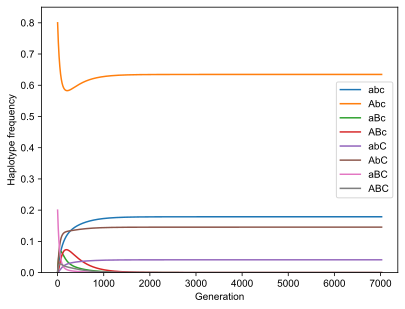

array([1.7880e-01, 6.3460e-01, 3.4328e-11, 9.8626e-11, 4.1017e-02,
       1.4558e-01, 7.8751e-12, 2.2625e-11])

In [40]:
                      # abc,  Abc, aBc, ABc, abC,  AbC,  aBC,  ABC 
haplo_freq = np.array([0.00, 0.8, 0.0, 0.0, 0.00, 0.00, 0.2, 0.00])
overdom_vec = [0,0]
epi_vec = [0.002, 0.004, 0.004, 0.008]

plot_dyn_haplo(haplo_freq, max_gen, get_selection_mat(overdom_vec, epi_vec), [0,0], [0.01,0.02])

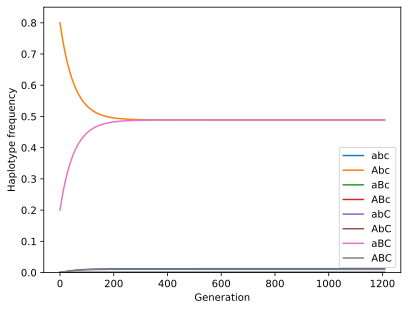

array([1.2299e-02, 4.8873e-01, 1.1712e-05, 4.6871e-07, 6.1436e-07,
       1.1664e-05, 4.8873e-01, 1.0214e-02])

In [37]:
# Example with migration
plot_dyn_haplo(haplo_freq, max_gen, get_selection_mat(overdom_vec, epi_vec), [0.01,0.01], [0.001, 0.000001])


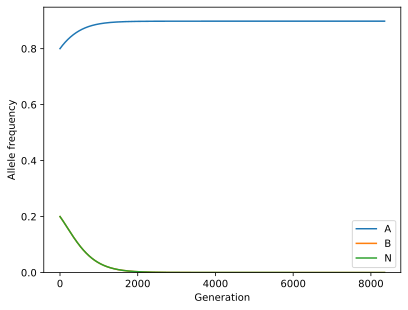

[np.float64(0.8981732842269058),
 np.float64(1.7423272442659702e-10),
 np.float64(0.000118558064510278)]

In [38]:
# Plotting dynamics
plot_dyn_freqs(haplo_freq, max_gen, get_selection_mat(overdom_vec, epi_vec), [0,0], [0.001, 0.000001])

### different r between A and B. With architecture A-B-N

In [351]:
max_gen = 50000
overdom = [0.03,0.03]
epi_vec = [0.03,0.06,0.06,0.12]
rab = [1e-6,1e-2,1e-1]
mig_vec = [0,0]

In [352]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]

['B', 'N']


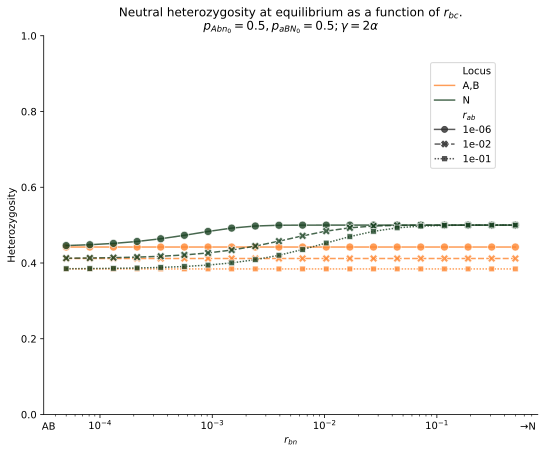

<Figure size 620x600 with 0 Axes>

In [275]:
## Fig paper
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rab,
                         title = 'Neutral heterozygosity at equilibrium as a function of $r_{bc}$.\n$p_{Abn_0}=0.5, p_{aBN_0}=0.5; \\gamma = 2\\alpha$',
                         width=6.2,
                         height=6,
                         filename = '../Fig/3_loci/fighet_pA0.5pB0.5_codominant_ABN.svg') 

In [276]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]

['B', 'N']


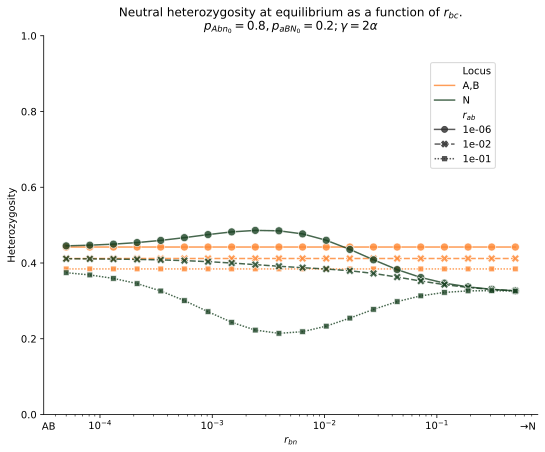

<Figure size 620x600 with 0 Axes>

In [277]:
# Fig 4A Poster | Fig Paper
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rab,
                         title = 'Neutral heterozygosity at equilibrium as a function of $r_{bc}$.\n$p_{Abn_0}=0.8, p_{aBN_0}=0.2; \\gamma = 2\\alpha$',
                         width=6.2,
                         height=6,
                         filename = '../Fig/3_loci/fighet_pA0.8pB0.2_codominant_ABN.svg') 

['B', 'N']


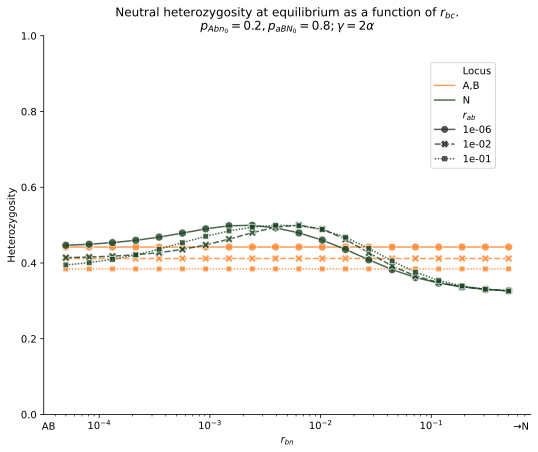

<Figure size 620x600 with 0 Axes>

In [278]:
#Switching initial freqs
haplo_freq = [0. , 0.2, 0. , 0. , 0. , 0. , 0.8, 0.]
# Fig 4A Poster | Fig Paper
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rab,
                         title = 'Neutral heterozygosity at equilibrium as a function of $r_{bc}$.\n$p_{Abn_0}=0.2, p_{aBN_0}=0.8; \\gamma = 2\\alpha$',
                         width=6.2,
                         height=6,
                         filename = '../Fig/3_loci/fighet_pA0.2pB0.8_codominant_ABN.svg') 


### Dynamics

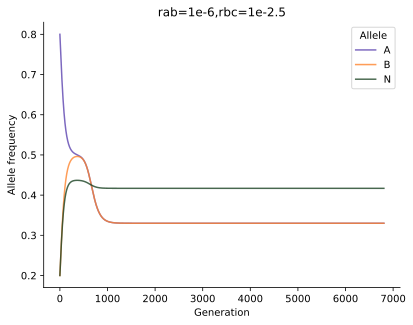

[np.float64(0.32992764939873126),
 np.float64(0.32992764939873104),
 np.float64(0.4168723864893023)]

In [364]:
# with 0.8, 0.2
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
plot_dyn_freqs(haplo_freq,
               max_gen, 
               get_selection_mat(overdom, epi_vec), 
               mig_vec, [1e-6,1*10**(-2.5)],
               title="rab=1e-6,rbc=1e-2.5",
               filename="../Fig/3_loci/dynamics_rab1e-6_rbn1e-2.5.svg")

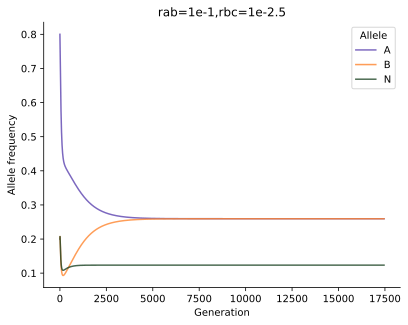

[np.float64(0.2595070850255515),
 np.float64(0.25950708417137835),
 np.float64(0.12348865975712432)]

In [365]:
# with 0.8, 0.2
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
plot_dyn_freqs(haplo_freq,
               max_gen, 
               get_selection_mat(overdom, epi_vec), 
               mig_vec, [1e-1,1*10**(-2.5)],
               title="rab=1e-1,rbc=1e-2.5",
               filename="../Fig/3_loci/dynamics_rab1e-1_rbn1e-2.5.svg")

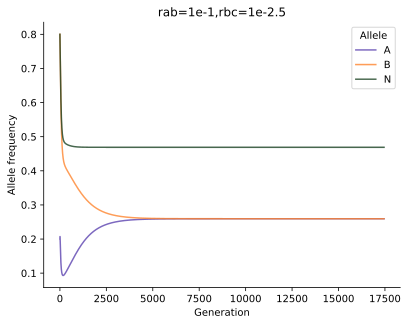

[np.float64(0.25950708417137325),
 np.float64(0.2595070850255573),
 np.float64(0.4688749278085858)]

In [366]:
# with 0.2, 0.8
haplo_freq = [0. , 0.2, 0. , 0. , 0. , 0. , 0.8, 0.]
plot_dyn_freqs(haplo_freq,
               max_gen, 
               get_selection_mat(overdom, epi_vec), 
               mig_vec, [1e-1,1*10**(-2.5)],
               title="rab=1e-1,rbc=1e-2.5",
               filename="../Fig/3_loci/dynamics_0.2,0.8_rab1e-1_rbn1e-2.5.svg")

#### Individual trajectories

In [79]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]

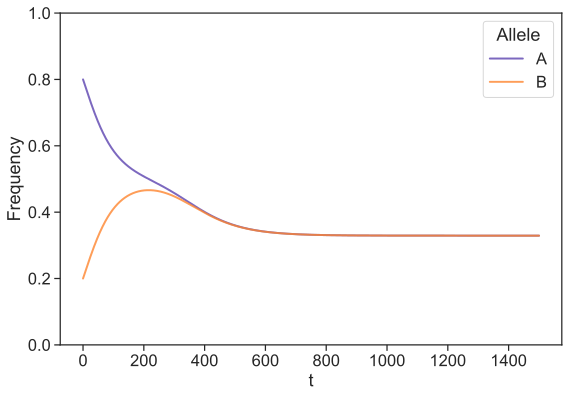

In [85]:
palette = {'A':'#5C43AF','B':'#FE842F', 'N':'#194122', 'C': '#194122'}
# y = 2a
sns.set(font_scale=1.5)
sns.set_style("ticks")
output = simulate_pop_3(haplo_freq, 1500, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.003924])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='Allele', value_name='Frequency')

plt.figure(figsize=(6*1.5, 6))
sns.lineplot(data = dfalleles[dfalleles.Allele!='C'], x='t', y='Frequency', hue='Allele', palette=palette, alpha=0.8, linewidth=2)
plt.ylim(0,1)
plt.show()
#plt.savefig('../Fig/3_loci/figfreqs_2loci_2a.svg')

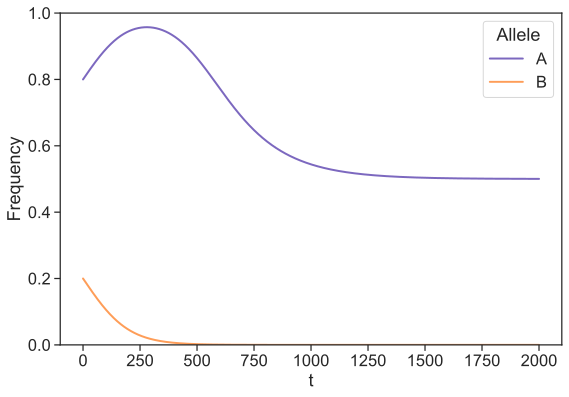

In [78]:
output = simulate_pop_3(haplo_freq, 2000, get_selection_mat([0.01,0.01], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.003924])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='Allele', value_name='Frequency')

plt.figure(figsize=(6*1.5, 6))
sns.lineplot(data = dfalleles[dfalleles.Allele!='C'], x='t', y='Frequency', hue='Allele', palette=palette, alpha=0.8, linewidth=2)
plt.ylim(0,1)
plt.show()
#plt.savefig('../Fig/3_loci/figfreqs_2loci_6a.svg')


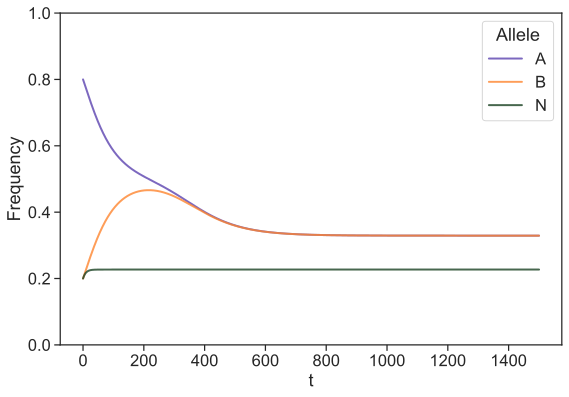

In [81]:
# y = 2a
output = simulate_pop_3(haplo_freq, 1500, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.1])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='Allele', value_name='Frequency')
dfalleles.Allele = dfalleles.Allele.replace('C','N')

plt.figure(figsize=(6*1.5, 6))
sns.lineplot(data = dfalleles, x='t', y='Frequency', hue='Allele', palette=palette, alpha=0.8, linewidth=2)
plt.ylim(0,1)
plt.show()
#plt.savefig('../Fig/3_loci/figfreqs_3loci_2a_rbc1e-1.svg')

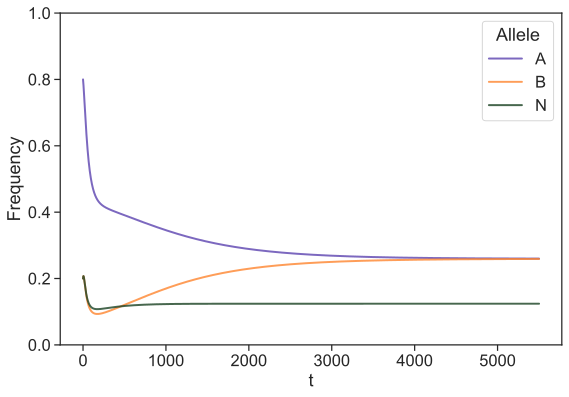

In [82]:
# y = 2a
output = simulate_pop_3(haplo_freq, 5500, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.1,0.003])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='Allele', value_name='Frequency')
dfalleles.Allele = dfalleles.Allele.replace('C','N')

plt.figure(figsize=(6*1.5, 6))
sns.lineplot(data = dfalleles, x='t', y='Frequency', hue='Allele', palette=palette, alpha=0.8, linewidth=2)
plt.ylim(0,1)
plt.show()
#plt.savefig('../Fig/3_loci/figfreqs_3loci_2a_rab0.1_rbc1e-2.5.svg')

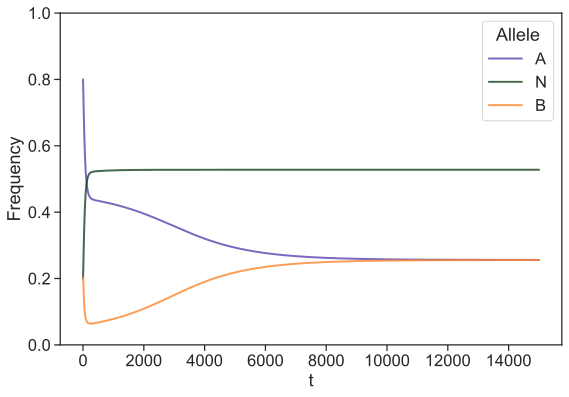

In [83]:
# y = 2a
output = simulate_pop_3(haplo_freq, 15000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [0.002,0.430])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='Allele', value_name='Frequency')

dfalleles.Allele = dfalleles.Allele.replace('B','N')
dfalleles.Allele = dfalleles.Allele.replace('C','B')

plt.figure(figsize=(6*1.5, 6))
sns.lineplot(data = dfalleles, x='t', y='Frequency', hue='Allele', palette=palette, alpha=0.8, linewidth=2)
plt.ylim(0,1)

plt.show()
#plt.savefig('../Fig/3_loci/figfreqs_3loci_2a_neutb_rab0.002_rab2e-3.svg')

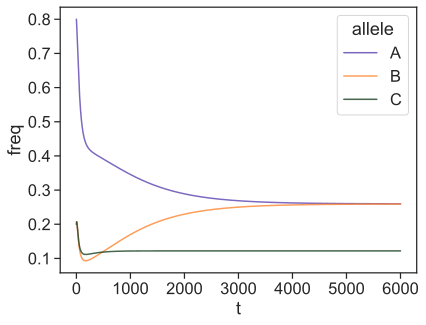

In [86]:
output = simulate_pop_3(haplo_freq, 6000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.1,0.003924])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='allele', value_name='freq')
sns.lineplot(data = dfalleles, x='t', y='freq', hue='allele', palette=palette, alpha=0.8)
plt.show()
#plt.savefig('../Fig/3_loci/figfreqsB.svg')

### Recessive DMIs

In [367]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
overdom = [0.03,0.03]
epi_vec = [0,0.06,0.06,0.12]
rab = [1e-10,1e-2,1e-1]

['B', 'N']


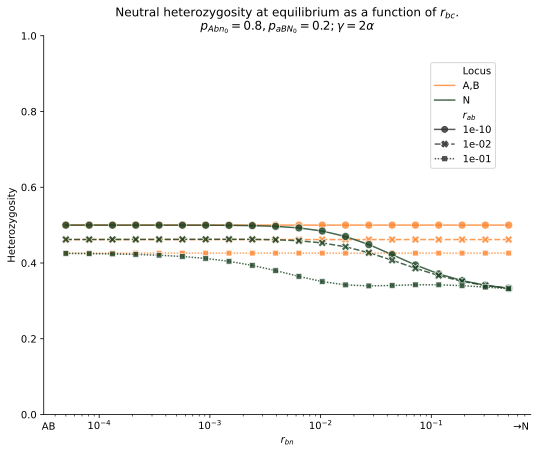

<Figure size 620x600 with 0 Axes>

In [280]:
# Fig 4A Poster | Fig Paper
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rab,
                         title = 'Neutral heterozygosity at equilibrium as a function of $r_{bc}$.\n$p_{Abn_0}=0.8, p_{aBN_0}=0.2; \\gamma = 2\\alpha$',
                         width=6.2,
                         height=6,
                         filename = '../Fig/3_loci/fighet_pA0.8pB0.2_recessive_ABN.svg') 

['B', 'N']


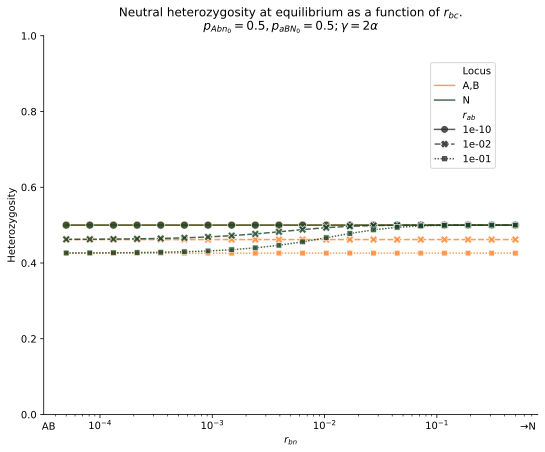

<Figure size 620x600 with 0 Axes>

In [281]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rab,
                         title = 'Neutral heterozygosity at equilibrium as a function of $r_{bc}$.\n$p_{Abn_0}=0.5, p_{aBN_0}=0.5; \\gamma = 2\\alpha$',
                         width=6.2,
                         height=6,
                         filename = '../Fig/3_loci/fighet_pA0.5pB0.5_recessive_ABN.svg')

>There is no increase in neutral heterozygosity with recessive incompatibilities

And for neutral diversity between the incompatibility

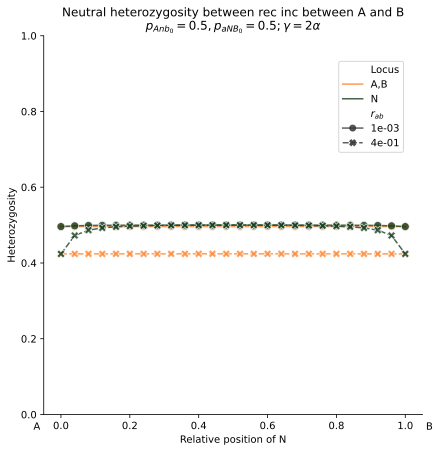

In [368]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
plot_heterozygosity_dist_neutb(haplo_freq,
                              max_gen,
                              get_selection_mat(overdom, epi_vec, neutb=True),
                              [0,0],
                              [0.001,0.432],
                              title = 'Neutral heterozygosity between rec inc between A and B\n$p_{Anb_0}=0.5, p_{aNB_0}=0.5; \\gamma = 2\\alpha$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/fighet_pA0.5pB0.5_recessive_ANB.svg')

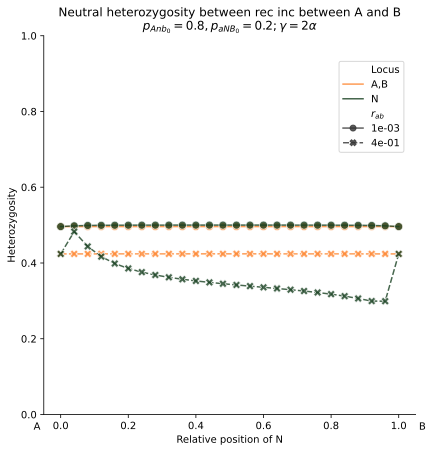

In [369]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
plot_heterozygosity_dist_neutb(haplo_freq,
                              max_gen,
                              get_selection_mat(overdom, epi_vec, neutb=True),
                              [0,0],
                              [0.001,0.432],
                              title = 'Neutral heterozygosity between rec inc between A and B\n$p_{Anb_0}=0.8, p_{aNB_0}=0.2; \\gamma = 2\\alpha$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/fighet_pA0.8pB0.2_recessive_ANB.svg')

### Rare C linked to B

In [ ]:
#             abc, Abc, aBc,  ABc, abC, AbC, aBC,  ABC,
haplo_freq = [0. , 0.5, 0.49, 0. , 0. , 0. , 0.01, 0.]
overdom = [0.03,0.03]
epi_vec = [0.03,0.06,0.06,0.12]
rab = [0,0.0001,0.001,0.01,0.1,0.5]

In [ ]:
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rab,
                         yaxis = 'freq',
                         title = 'Final derived allele frequencies\np_A0=0.5, p_B0=0.5, p_C0=0.01; g=2a') 

In [ ]:
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         [0,0.0001,0.1],
                         title = 'Equilibrium heterozygosity\np_A0=0.5, p_B0=0.5; g=2a') 

In [ ]:
data = []
alleles = ['A', 'B', 'C']
rab = [0,0.0001,0.001,0.01,0.1,0.5]

for feature_idx, feature in enumerate(out):
    for x_value, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': rab[feature_idx]})

# Create a DataFrame
df = pd.DataFrame(data)
df = df[df['allele']=='C']

# Plot using Seaborn
sns.lineplot(data=df, x='r', y='freq', hue='allele', style='r_ab', markers=True, alpha=0.7)
plt.xscale('log')
plt.title("Final frequency of C as a function of r_bc.\np_A0=0.5, p_B0=0.5, p_C0=0.01; a=g/2")
plt.show()

In [ ]:
plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.001,0.001])

In [ ]:
# abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,0.5,0.49,0,0,0,0.01,0]

In [ ]:
# Plotting different r between A and B
out = []
for rab in [0,0.0001,0.001,0.01,0.1,0.5]:
    freqs = []
    for i in np.linspace(-4,0,20):
        output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [rab, 0.5*10**(i)])
        freqs.append([0.5*10**(i), get_alleles(output[-1])])
    out.append(freqs)


In [ ]:
data = []
alleles = ['A', 'B', 'C']
rab = [0,0.0001,0.001,0.01,0.1,0.5]

for feature_idx, feature in enumerate(out):
    for x_value, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': rab[feature_idx]})

# Create a DataFrame
df = pd.DataFrame(data)
df = df[df['allele']=='C']

# Plot using Seaborn
sns.lineplot(data=df, x='r', y='freq', hue='allele', style='r_ab', markers=True, alpha=0.7)
plt.xscale('log')
plt.title("Final frequency of C as a function of r_bc.\np_A0=0.5, p_B0=0.5, p_C0=0.01; a=g")
plt.show()

C increases frequency with increasing r

### Less rare C (C_0=0.05) and different initial condition for A (0.8) and B (0.2)

In [ ]:
# abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,0.8,0.15,0,0,0,0.05,0]

In [ ]:
# Plotting different r between A and B
out = []
for rab in [0,0.0001,0.001,0.01,0.1,0.5]:
    freqs = []
    for i in np.linspace(-4,0,20):
        output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [rab, 0.5*10**(i)])
        freqs.append([0.5*10**(i), get_alleles(output[-1])])
    out.append(freqs)


In [ ]:
data = []
alleles = ['A', 'B', 'C']
rab = [0,0.0001,0.001,0.01,0.1,0.5]

for feature_idx, feature in enumerate(out):
    for x_value, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': rab[feature_idx]})

# Create a DataFrame
df = pd.DataFrame(data)
df = df[df['allele']=='C']

# Plot using Seaborn
sns.lineplot(data=df, x='r', y='freq', hue='allele', style='r_ab', markers=True, alpha=0.7)
plt.xscale('log')
plt.title("Final frequency of C as a function of r_bc.\np_A0=0.8, p_B0=0.2, p_C0=0.01; a=g")
plt.show()

In [ ]:
plot_dyn_haplo(haplo_freq, 50000, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.01])

In [ ]:
plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.01])

### With P_B0 > P_A0

In [ ]:
# abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,0.2,0.75,0,0,0,0.05,0]

In [ ]:
# Plotting different r between A and B
out = []
for rab in [0,0.0001,0.001,0.01,0.1,0.5]:
    freqs = []
    for i in np.linspace(-4,0,20):
        output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [rab, 0.5*10**(i)])
        freqs.append([0.5*10**(i), get_alleles(output[-1])])
    out.append(freqs)


In [ ]:
data = []
alleles = ['A', 'B', 'C']
rab = [0,0.0001,0.001,0.01,0.1,0.5]

for feature_idx, feature in enumerate(out):
    for x_value, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': rab[feature_idx]})

# Create a DataFrame
df = pd.DataFrame(data)
df = df[df['allele']=='C']

# Plot using Seaborn
sns.lineplot(data=df, x='r', y='freq', hue='allele', style='r_ab', markers=True, alpha=0.7)
plt.xscale('log')
plt.title("Final frequency of C as a function of r_bc.\np_A0=0.2, p_B0=0.8, p_C0=0.05; a=g")
plt.show()

In [ ]:
haplo_freq = [0,0.2,0.75,0,0,0,0.05,0]
plot_dyn_haplo(haplo_freq, 50000, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.01])

In [ ]:
plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [0.01,0.01], title="Allele dynamics.\np_A0=0.2, p_B0=0.8; P_C0=0.05; a=g")

In [ ]:
#plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.01,0.01], title="Allele dynamics.\np_A0=0.2, p_B0=0.8; P_C0=0.05; a=g")

In [ ]:
output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [0.001,0.001])
    
# Show the last few lines of the data table
#print(output[-5:])

# Plot the output
x_range = np.arange(len(output))
allele_freq = np.array(map(get_alleles, output))

In [ ]:
selection_mat_tst = get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12])

In [ ]:
selection_mat_tst

In [ ]:
geno_mat = np.outer(output[-1], output[-1])
geno_mat

In [ ]:
#np.dot(output[-1],selection_mat_tst)
outwmarg = np.array([np.dot(output[i],selection_mat_tst) for i in range(len(output))])
x_range = np.arange(len(output))
haplotypes = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"]

for i in range(len(haplotypes)):
    plt.plot(x_range, outwmarg[:, i], label=haplotypes[i])
    
#plt.ylim(0, np.max(outwmarg))
plt.xlabel("Generation")
plt.ylabel("Marginal fitness")
plt.legend()
plt.show()


In [ ]:
#marginal fitnesses for one generation:
wmarg = outwmarg[0]
wmarg


In [ ]:
for feature_idx, feature in enumerate(output):
    for x_value, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': rab[feature_idx]})

# Create a DataFrame
df = pd.DataFrame(data)
df = df[df['allele']!='A']

In [ ]:
x_range = np.arange(len(output))
haplotypes = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"]

df_haplo = pd.DataFrame(output, columns=haplotypes)
df_haplo['t'] = range(len(output))
df_haplo = df_haplo[['t'] + haplotypes]

longdf = df_haplo.melt(id_vars=['t'], var_name='haplotype', value_name='freq')

In [ ]:
# Pivot to wide format
wide_df = longdf.pivot(index='t', columns='haplotype', values='freq')

# Create a stacked area plot
fig, ax = plt.subplots(figsize=(10, 6))
haplos = wide_df.columns
ax.stackplot(wide_df.index, wide_df.T, labels=haplos, alpha=0.8, colors=sns.color_palette("tab10", len(haplos)))

# Customize the plot
ax.set_title("Müller Plot of Haplotypes", fontsize=16)
ax.set_xlabel("t", fontsize=14)
ax.set_ylabel("freq", fontsize=14)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## Architecture A-N-B

In [349]:
max_gen = 50000
overdom = [0.03,0.03]
epi_vec = [0.03,0.06,0.06,0.12]
rab = [1e-6,0.432]

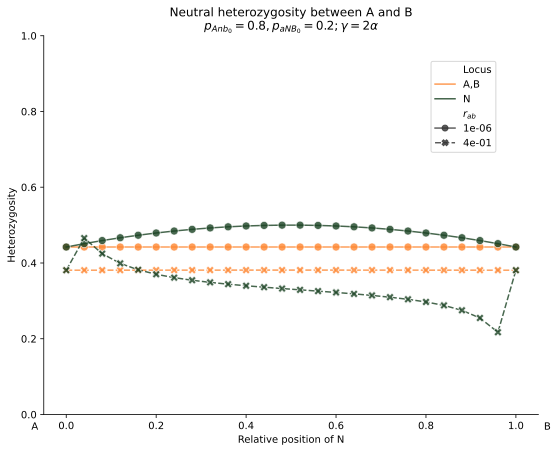

<Figure size 620x600 with 0 Axes>

In [285]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
plot_heterozygosity_dist_neutb(haplo_freq,
                              max_gen,
                              get_selection_mat(overdom, epi_vec, neutb=True),
                              [0,0],
                              rab,
                              title = 'Neutral heterozygosity between A and B\n$p_{Anb_0}=0.8, p_{aNB_0}=0.2; \\gamma = 2\\alpha$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/fighet_pA0.8pB0.2_codominant_ANB.svg')

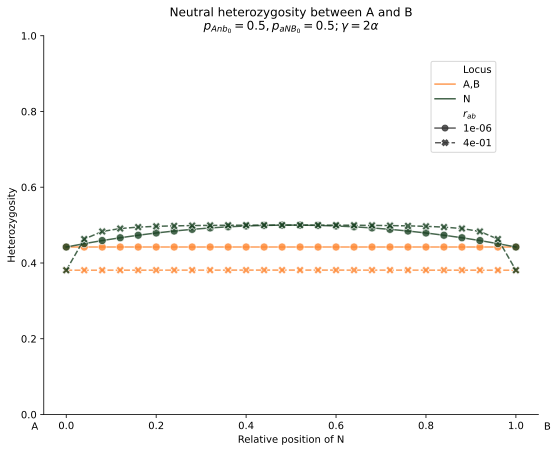

<Figure size 620x600 with 0 Axes>

In [286]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
plot_heterozygosity_dist_neutb(haplo_freq,
                              max_gen,
                              get_selection_mat(overdom, epi_vec, neutb=True),
                              [0,0],
                              rab,
                              title = 'Neutral heterozygosity between A and B\n$p_{Anb_0}=0.5, p_{aNB_0}=0.5; \\gamma = 2\\alpha$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/fighet_pA0.5pB0.5_codominant_ANB.svg')

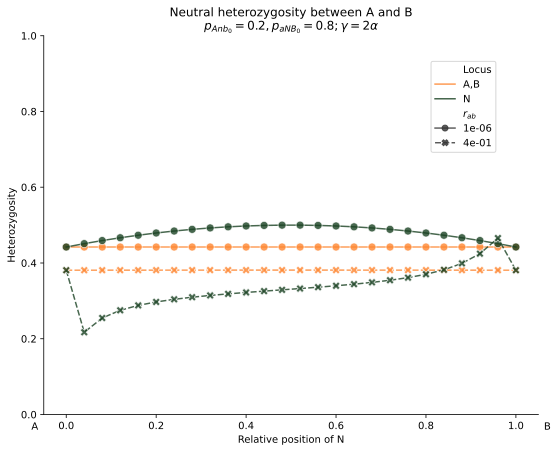

<Figure size 620x600 with 0 Axes>

In [287]:
haplo_freq = [0. , 0.2, 0. , 0. , 0. , 0. , 0.8, 0.]
plot_heterozygosity_dist_neutb(haplo_freq,
                              max_gen,
                              get_selection_mat(overdom, epi_vec, neutb=True),
                              [0,0],
                              rab,
                              title = 'Neutral heterozygosity between A and B\n$p_{Anb_0}=0.2, p_{aNB_0}=0.8; \\gamma = 2\\alpha$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/fighet_pA0.2pB0.8_codominant_ANB.svg')

## No DMIs, heterosis only

In [299]:
rab = [1e-6,1e-2, 1e-1]

['B', 'N']


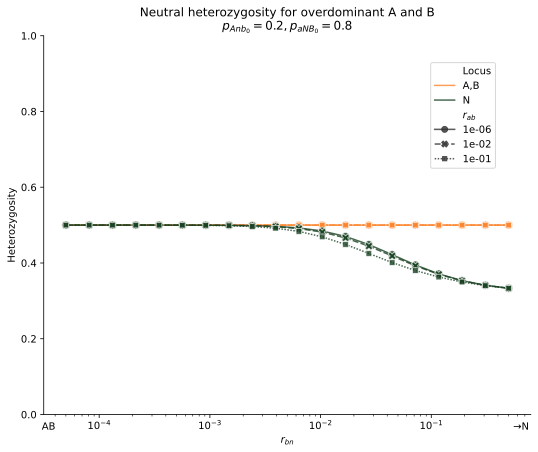

<Figure size 620x600 with 0 Axes>

In [300]:
haplo_freq = [0. , 0.2, 0. , 0. , 0. , 0. , 0.8, 0.]
plot_heterozygosity_dist(haplo_freq,
                              max_gen,
                              get_selection_mat(overdom, [0,0,0,0]),
                              [0,0],
                              rab,
                              title = 'Neutral heterozygosity for overdominant A and B\n$p_{Anb_0}=0.2, p_{aNB_0}=0.8$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/overdominance_pA0.2pB0.8_ABN.svg')

['B', 'N']


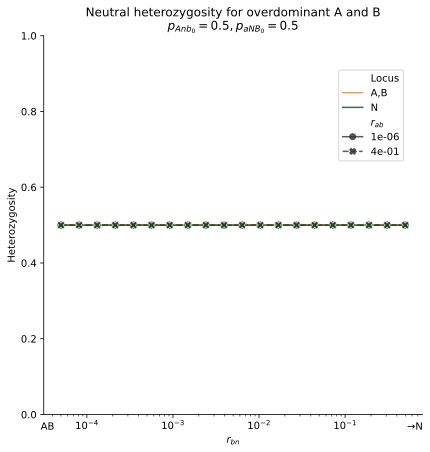

In [350]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
plot_heterozygosity_dist(haplo_freq,
                              max_gen,
                              get_selection_mat(overdom, [0,0,0,0]),
                              [0,0],
                              rab,
                              title = 'Neutral heterozygosity for overdominant A and B\n$p_{Anb_0}=0.5, p_{aNB_0}=0.5$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/overdominance_pA0.5pB0.5_ABN.svg')

In [ ]:
## PPT figs

# haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
# plot_heterozygosity_dist(haplo_freq,
#                               max_gen,
#                               get_selection_mat(overdom, [0,0,0,0]),
#                               [0,0],
#                               rab,
#                               title = 'Neutral heterozygosity for overdominant A and B\n$p_{Anb_0}=0.5, p_{aNB_0}=0.5$',
#                               width=6.2,
#                               height=6,
#                               filename = '../Fig/3_loci/overdominance_pA0.5pB0.5_ABN.svg')

### Only codominant DMIs

In [40]:
rab = [1e-6,1e-2, 1e-1]
gamma = 0.06
codominant_dmis = [gamma/2,gamma,gamma,2*gamma]
recessive_dmis = [0,gamma,gamma,2*gamma]

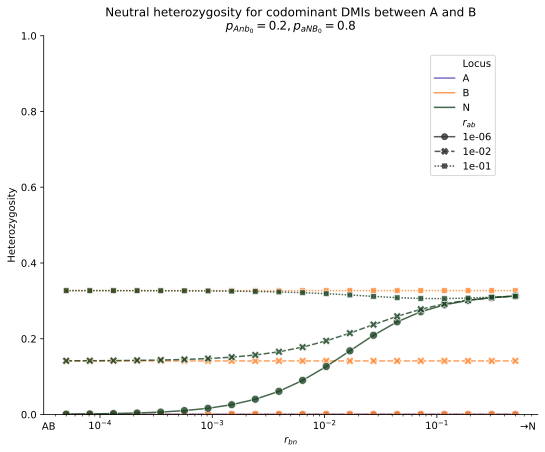

<Figure size 620x600 with 0 Axes>

In [292]:
haplo_freq = [0. , 0.2, 0. , 0. , 0. , 0. , 0.8, 0.]
plot_heterozygosity_dist(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], codominant_dmis),
                              [0,0],
                              rab,
                              allelelist=['A', 'B', 'N'],
                              title = 'Neutral heterozygosity for codominant DMIs between A and B\n$p_{Anb_0}=0.2, p_{aNB_0}=0.8$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/codominantDMIs_pA0.2pB0.8_ABN.svg')

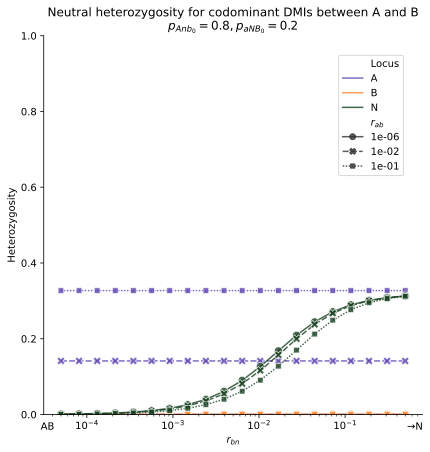

In [377]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
plot_heterozygosity_dist(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], codominant_dmis),
                              [0,0],
                              rab,
                              allelelist=['A', 'B', 'N'],
                              title = 'Neutral heterozygosity for codominant DMIs between A and B\n$p_{Anb_0}=0.8, p_{aNB_0}=0.2$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/codominantDMIs_pA0.8pB0.2_ABN.svg')

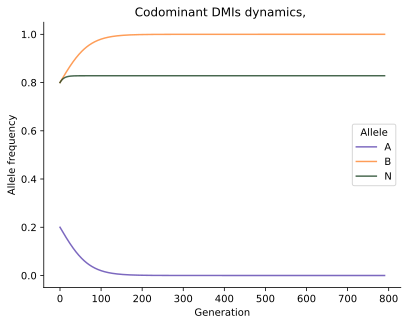

3.1747937612180976e-11
2.155449094787265e-05
0.28452070478208724


In [370]:
# with 0.2, 0.8
haplo_freq=[0. , 0.2, 0. , 0. , 0. , 0. , 0.8, 0.]
res = plot_dyn_freqs(haplo_freq,
               max_gen, 
               get_selection_mat([0,0], codominant_dmis), 
               mig_vec, [1e-6,1e-1],
               title="Codominant DMIs dynamics, ")
for i in res:
    print(get_heterozygosity(i))

### Only recessive DMIs

In [373]:
rab = [1e-4,1e-2,1e-1]

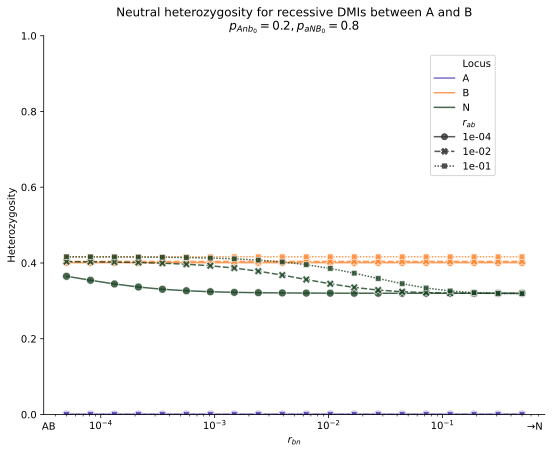

<Figure size 620x600 with 0 Axes>

In [296]:
haplo_freq = [0. , 0.2, 0. , 0. , 0. , 0. , 0.8, 0.]
plot_heterozygosity_dist(haplo_freq,
                              max_gen*2,
                              get_selection_mat([0,0], recessive_dmis),
                              [0,0],
                              rab,
                              allelelist=['A', 'B', 'N'],
                              title = 'Neutral heterozygosity for recessive DMIs between A and B\n$p_{Anb_0}=0.2, p_{aNB_0}=0.8$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/recessiveDMIs_pA0.2pB0.8_ABN.svg')

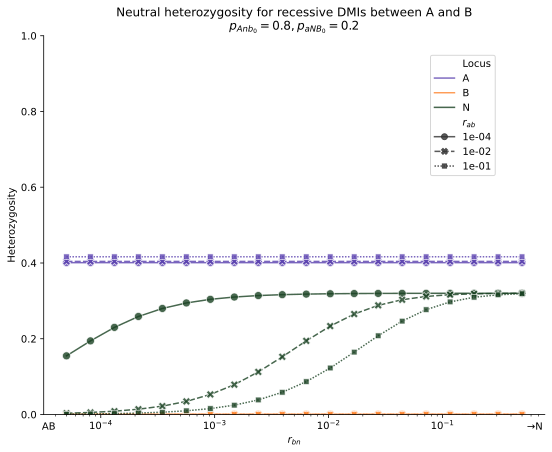

<Figure size 620x600 with 0 Axes>

In [297]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
plot_heterozygosity_dist(haplo_freq,
                              max_gen*2,
                              get_selection_mat([0,0], recessive_dmis),
                              [0,0],
                              rab,
                              allelelist=['A', 'B', 'N'],
                              title = 'Neutral heterozygosity for recessive DMIs between A and B\n$p_{Anb_0}=0.8, p_{aNB_0}=0.2$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/codominantDMIs_pA0.8pB0.2_ABN.svg')

#### Within the DMI

In [374]:
rab = [1e-6, 0.432]

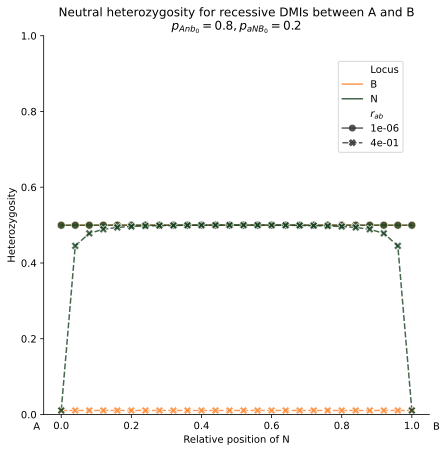

In [375]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
plot_heterozygosity_dist_neutb(haplo_freq,
                              max_gen*2,
                              get_selection_mat([0,0], recessive_dmis, neutb=True),
                              [0,0],
                              rab,
                              allelelist=['A', 'B', 'N'],
                              title = 'Neutral heterozygosity for recessive DMIs between A and B\n$p_{Anb_0}=0.8, p_{aNB_0}=0.2$',
                              width=6.2,
                              height=6,
                              filename = '../Fig/3_loci/recessiveDMIs_pA0.5pB0.5_ANB.svg')

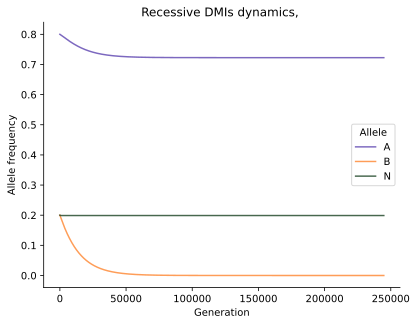

0.4009314697360369
8.915203686399309e-09
0.31869311102356956


In [298]:
haplo_freq=[0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
res = plot_dyn_freqs(haplo_freq,
               max_gen*15, 
               get_selection_mat([0,0], recessive_dmis), 
               mig_vec, [1e-4,1e-2],
               title="Recessive DMIs dynamics, ")
for i in res:
    print(get_heterozygosity(i))



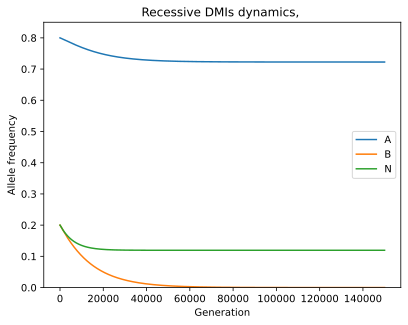

0.4009294120523623
8.339984236771514e-06
0.21033429986247176


In [116]:
haplo_freq=[0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
res = plot_dyn_freqs(haplo_freq,
               max_gen*3, 
               get_selection_mat([0,0], [0,0.06,0.06,0.12]), 
               mig_vec, [1e-4,1e-4],
               title="Recessive DMIs dynamics, ")
for i in res:
    print(get_heterozygosity(i))

## ESEB 2025 plots

### Poster

In [97]:
#plt.rcParams.update({'font.size': 18}) ## Return to orig
plt.rcParams.update({'font.size': 22}) ## Return to orig

In [98]:
def plot_heterozygosity_dist_poster(haplo_freq, 
                             max_gen, 
                             selection_mat, 
                             mig, 
                             recombination_list, 
                             palette = {'A':'#5C43AF','B':'#FE842F', 'N':'#194122', 'A,B':'#FE842F'},
                             yaxis ='het',
                             allelelist = ['B', 'N'],
                             rmin=-4,rmax=0,steps=20,
                             legendbelow=False,
                             **kwargs):
    # Plotting different r between A and B
    out = []
    outhaplo = []
    
    #for rab in [0,0.0001,0.001,0.01,0.1,0.5]:
    for rab in recombination_list:
        freqs = []
        for i in np.linspace(rmin,rmax,steps):
            output = simulate_pop_3(haplo_freq, max_gen, selection_mat, mig, [rab, 0.5*10**(i)])
            freqs.append([0.5*10**(i), get_alleles(output[-1])])
            outhaplo.append([len(output), rab, 0.5*10**(i)])
            outhaplo[-1].extend(output[-1])
        out.append(freqs)
    
    data = []
    haplodf = pd.DataFrame(outhaplo, columns=['tmax','rab', 'rbn', 'abc',  'Abc', 'aBc', 'ABc', 'abC', 'AbC', 'aBC', 'ABC'])
    alleles = ['A', 'B', 'C']

    for feature_idx, feature in enumerate(out):
        for x_value, y_values in feature:
            for allele, y in zip(alleles, y_values):
                data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': recombination_list[feature_idx]})


    # Create a DataFrame
    df = pd.DataFrame(data)
    df['het'] = 1 - (((df.freq)**2) + ((1-df.freq)**2)) # Calculate heterozygosity
    df['allele'] = df['allele'].replace({'C':'N'})       # Replace 
    df = df[df['allele'].isin(allelelist)]
    if ('A' not in allelelist and yaxis=='het'): # Change the label of B to A,B for clarity
        df['allele'] = df['allele'].replace({'B':'A,B'})

    df['r_ab'] = [f"{i:.0e}" for i in df['r_ab']]


    ## Get custom height and width if provided
    height = kwargs.get("height", 6)
    width = kwargs.get("width", height * 1.3)  # default aspect ratio if width not provided
    aspect = width / height

    #dashesdict = {'A':(2, 2),'B':(2, 3), 'N':(2, 5), 'A,B':(2, 3)}
    markerlist = ["X", "P", "^", "o"] if len(pd.unique(df['r_ab']))==3 else ["o"]
    
    figfreqs = sns.relplot(data=df, x='r', y=yaxis, hue='allele',
        style='r_ab', kind="line", markers=markerlist,
        palette=palette, alpha=0.8, 
        dashes=[(4,1),(4,1.5),(4,1.25)],
        height=height, aspect=aspect)


    
    legend = figfreqs._legend  
    if legend:
        for text in legend.get_texts():
            if text.get_text() == "allele":
                if yaxis=='het':
                    text.set_text("Locus")  # Change label
                elif yaxis=='freq':
                    text.set_text("Allele")  
            elif text.get_text() == "r_ab":
                text.set_text(r"$r_{ab}$")             


        if legendbelow==True:
            # Move the legend to the upper right
            #legend.set_bbox_to_anchor((0.8, 0.78))  # Position it in the upper right corner
            #legend.set_frame_on(True)
    
    
            sns.move_legend(
                figfreqs, "lower center",
                bbox_to_anchor=(.5, -0.05), ncol=8, title=None, frameon=False,
            )

    
    
    for ax in figfreqs.axes.flat:
        for line in ax.lines:
            line.set_markersize(16) 

            # Change line color alpha only (line.get_color() returns RGB or RGBA string)
            lc = line.get_color()  # e.g. '#FE842F' or (r,g,b,a)
            # Convert color to RGBA tuple:
            rgba = mcolors.to_rgba(lc)
            # Replace alpha for line only, e.g. 0.3
            new_line_color = (rgba[0], rgba[1], rgba[2], 0.4)
            line.set_color(new_line_color)
            
            mfc = line.get_markerfacecolor() # Change markers to 0.8
            if isinstance(mfc, tuple) and len(mfc) == 4:
                new_mfc = (mfc[0], mfc[1], mfc[2], 0.8)  
                line.set_markerfacecolor(new_mfc)

            mec = line.get_markeredgecolor()
            if isinstance(mec, tuple) and len(mec) == 4:
                new_mec = (mec[0], mec[1], mec[2], 0.8)
                line.set_markeredgecolor(new_mec)
   
    plt.xlabel(r"$r_{bn}$")
    if yaxis=='het':
        plt.ylabel("Heterozygosity")
    elif yaxis=='freq':
        plt.ylabel("Frequency")

    # Get X-axis limits
    ax = figfreqs.ax
    xmin, xmax = ax.get_xlim()

    # Set log scale on x-axis
    ax.set_xscale('log')

    # ax.axhline(0.5, ls=':', linewidth=1, color='red', alpha = 0.5) # Red line at 0.5, for testing

    ax.text(0.01, -0.03, "AB", ha='center', va='top', fontsize=18, transform=ax.transAxes)
    ax.text(0.98, -0.03, "→N", ha='center', va='top', fontsize=18, transform=ax.transAxes)
    
    #ax = plt.subplot(111)
    #plt.xscale('log')
    #plt.ylim(0, np.max(df[yaxis])+0.05)
    if yaxis=='het':
        plt.ylim(-0.05, 0.55)
    else:
        plt.ylim(-0.05, 1.05)
    if "title" in kwargs.keys():
        plt.title(kwargs["title"])

    plt.grid(linewidth=0.5, alpha=0.5)
    
    plt.show()
    

    if "filename" in kwargs.keys():
        figfreqs.savefig(kwargs["filename"])
    return haplodf
    #return df
    #plt.savefig('fighet_ppt.svg')-

In [99]:
def plot_heterozygosity_dist_neutb_poster(haplo_freq, 
                                   max_gen, 
                                   selection_mat, 
                                   mig, 
                                   recombination_list, 
                                   palette = {'A':'#5C43AF','B':'#FE842F', 'N':'#194122', 'A,B':'#FE842F'},
                                   yaxis = 'het',
                                   allelelist = ['B', 'N'],
                                   npoints = 25, legendbelow=False,
                                   **kwargs): 
    # Plotting different r between A and B
    
    # Simulate population
    out = []
    outhaplo=[]
    everyn = int(100/npoints)
    for totr in recombination_list:
        for rab in range(0,101,everyn):
            freqs = []
            #for i in np.linspace(-4,0,20):
            r_ab = totr*rab/100
            r_bc = totr-(totr*rab/100)
            output = simulate_pop_3(haplo_freq, max_gen, selection_mat, [0,0], [r_ab, r_bc])
            freqs.append([r_ab, r_bc, totr, get_alleles(output[-1])])
            out.append(freqs)
            outhaplo.append([len(output), r_ab, r_bc])
            outhaplo[-1].extend(output[-1])

    #Extract allele data and create df
    data = []
    haplodf = pd.DataFrame(outhaplo, columns=['tmax','rab', 'rbc', 'anb',  'Anb', 'aNb', 'ANb', 'abN', 'AbN', 'aNB', 'ANB'])
    
    alleles = ['A', 'B', 'C']
    for feature_idx, feature in enumerate(out):
        for rab, rbc, totr, y_values in feature:
            for allele, y in zip(alleles, y_values):
                data.append({'rab': rab, 'rbc': rbc, 'pos': rab/totr, 'totr':totr, 'allele': allele, 'freq': y})

    df = pd.DataFrame(data)
    df = df.rename(columns={'totr': 'r_ab'})
    df['het'] = 1 - (((df.freq)**2) + ((1-df.freq)**2))
    df['allele'] = df['allele'].replace({'B':'N'})
    df['allele'] = df['allele'].replace({'A':'B'})
    df = df[df['allele'].isin(allelelist)]

    if ('A' not in allelelist and yaxis=='het'): # Change the label of B to A,B for clarity
        df['allele'] = df['allele'].replace({'B':'A,B'})

    df['r_ab'] = [f"{i:.0e}" for i in df['r_ab']] # Changing to scientific notation
    
    ## Get custom height and widrth
    height = kwargs.get("height", 6)
    width = kwargs.get("width", height * 1.3)  # default
    aspect = width / height
    
    #Plot
    figfreqs = sns.relplot(data=df[df['allele']!='C'], x='pos', y=yaxis, hue='allele',
                           style='r_ab', kind="line", markers=["X", "P", "^"],
                           palette=palette, alpha=0.8, 
                           dashes=[(4,1),(4,1.5),(4,1.25)],
                           height=height, aspect=aspect,
                           linewidth=2)


    legend = figfreqs._legend  
    if legend:
        for text in legend.get_texts():
            if text.get_text() == "allele":
                if yaxis=='het':
                    text.set_text("Locus")  # Change label
                elif yaxis=='freq':
                    text.set_text("Allele")  
            elif text.get_text() == "r_ab":
                text.set_text(r"$r_{ab}$")  
        
        if legendbelow==True:
            # Move the legend to the upper right
            # legend.set_bbox_to_anchor((0.8, 0.8))  # Position it in the upper right corner
            # legend.set_frame_on(True)  
    
            # Move legend to the bottom
            sns.move_legend(
                figfreqs, "lower center",
                bbox_to_anchor=(.5, -0.05), ncol=8, title=None, frameon=False,
            )


    for ax in figfreqs.axes.flat:
        for line in ax.lines:
            line.set_markersize(16)

                        # Change line color alpha only (line.get_color() returns RGB or RGBA string)
            lc = line.get_color()  # e.g. '#FE842F' or (r,g,b,a)
            # Convert color to RGBA tuple:
            rgba = mcolors.to_rgba(lc)
            # Replace alpha for line only, e.g. 0.3
            new_line_color = (rgba[0], rgba[1], rgba[2], 0.4)
            line.set_color(new_line_color)
            
            mfc = line.get_markerfacecolor() # Change markers to 0.8
            if isinstance(mfc, tuple) and len(mfc) == 4:
                new_mfc = (mfc[0], mfc[1], mfc[2], 0.8)  
                line.set_markerfacecolor(new_mfc)

            mec = line.get_markeredgecolor()
            if isinstance(mec, tuple) and len(mec) == 4:
                new_mec = (mec[0], mec[1], mec[2], 0.8)
                line.set_markeredgecolor(new_mec)


    plt.xlabel("Relative position of N")
    if yaxis=='het':
        plt.ylabel("Heterozygosity")
    elif yaxis=='freq':
        plt.ylabel("Frequency")

    # Get X-axis limits
    xmin, xmax = ax.get_xlim()

    # Add text "A" at the beginning and "B" at the end of the X-axis
    ax.text(0.005, -0.03, "A", ha='center', va='top', fontsize=18, transform=ax.transAxes)
    ax.text(0.985, -0.03, "B", ha='center', va='top', fontsize=18, transform=ax.transAxes)
    #ax.text(xmin-0.02, -0.03, "A", ha='center', va='top', fontsize=14, transform=ax.transData)
    #ax.text(xmax+0.02, -0.03, "B", ha='center', va='top', fontsize=14, transform=ax.transData)

    #ax = plt.subplot(111)
    if yaxis=='het':
        plt.ylim(-0.05, 0.55)
    else:
        plt.ylim(-0.05, 1.05)
        
    if "title" in kwargs.keys():
        plt.title(kwargs["title"])

    plt.grid(linewidth=0.5, alpha=0.5)   
    plt.show()

    # Save
    if "filename" in kwargs.keys():
        figfreqs.savefig(kwargs["filename"])

    return haplodf

In [737]:
## FIG 1

In [56]:
max_gen = 50000
overdom = [0.03,0.03]
epi_vec = [0.03,0.06,0.06,0.12]
rab = [1e-6,1e-2,1e-1]
mig_vec = [0,0]

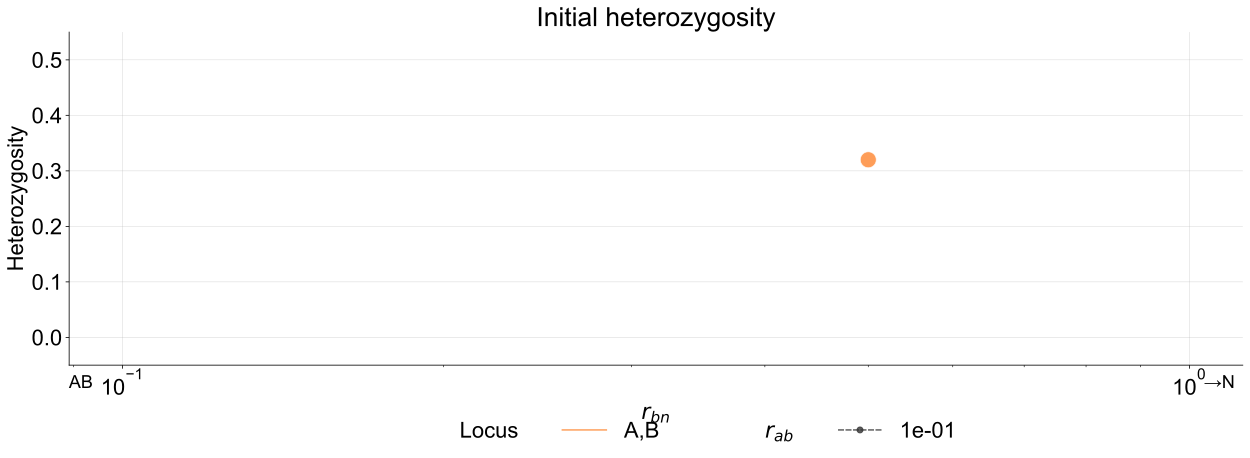

In [65]:
# INIT
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq, 
                         0, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         [1e-1],
                         title = 'Initial heterozygosity',
                         allelelist=['B'],
                         width=18,
                         height=6,
                         rmin=0, rmax=0, steps=1, legendbelow=True,
                         filename = '../Fig/3_loci/fig4A_init_0.svg') 

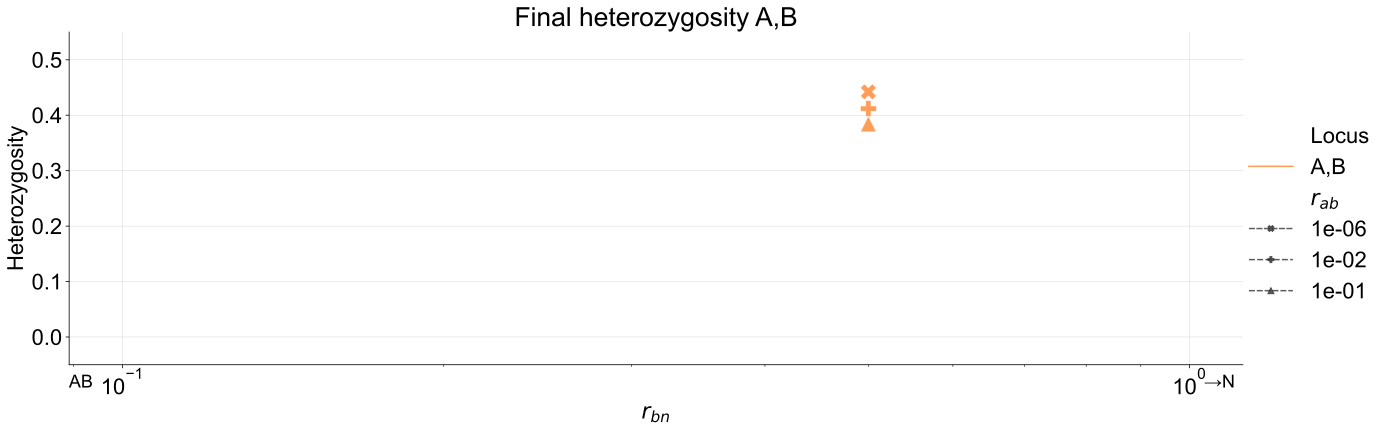

In [66]:
# END
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rab,
                         title = 'Final heterozygosity A,B',
                         allelelist=['B'],
                         width=18,
                         height=6,
                         rmin=0, rmax=0, steps=1,
                         filename = '../Fig/3_loci/fig4A_end.svg') 

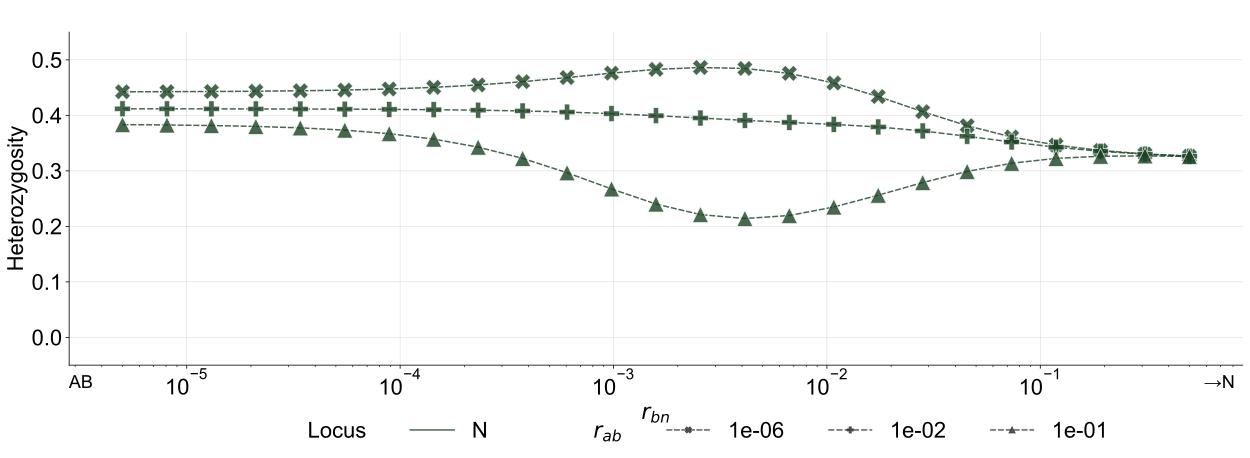

In [63]:
# INTERMEDIATE
df = plot_heterozygosity_dist_poster(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rab,
                         title = ' ',
                         allelelist=['N'],
                         width=18, # 18x6
                         height=6, 
                         rightside=True,            
                         rmin=-5, rmax=0, steps=25, legendbelow=True,
                         filename = '../Fig/3_loci/fig4A_N.svg') 


In [59]:
max_gen = 50000
overdom = [0.03,0.03]
epi_vec = [0.03,0.06,0.06,0.12]
rab = [1e-6,1e-2,1e-1]
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]

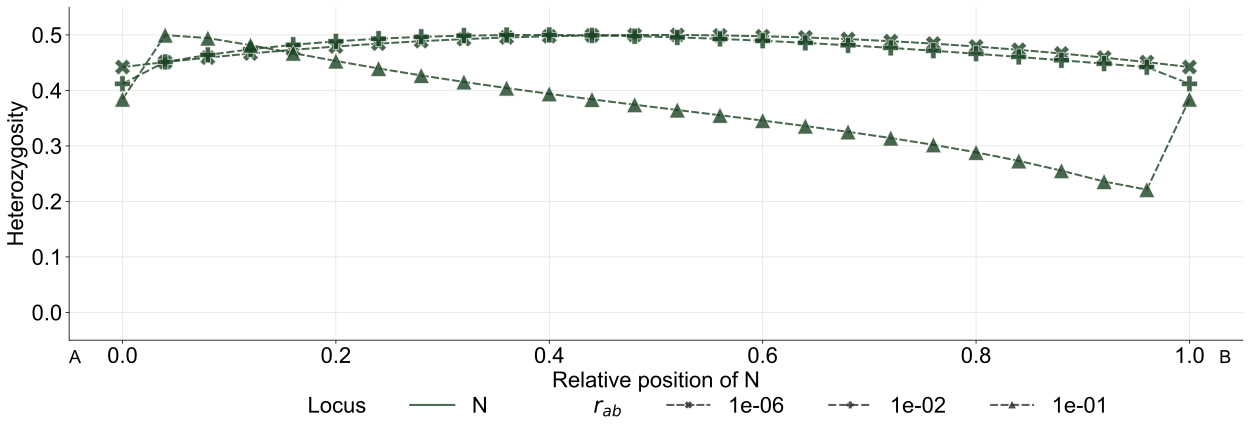

,tmax,rab,rbc,anb,Anb,aNb,ANb,abN,AbN,aNB,ANB
0,2901,0.000000e+00,1.000000e-06,0.000000,0.329924,0.340148,0.000000,0.000000,0.000004,0.329924,0.000000e+00
1,50001,4.000000e-08,9.600000e-07,0.013609,0.329709,0.326539,0.000215,0.000213,0.000003,0.329711,1.472159e-07
2,50001,8.000000e-08,9.200000e-07,0.027218,0.329513,0.312930,0.000411,0.000408,0.000003,0.329516,2.938896e-07
3,50001,1.200000e-07,8.800000e-07,0.040826,0.329334,0.299322,0.000590,0.000586,0.000003,0.329338,4.400682e-07
4,50001,1.600000e-07,8.400000e-07,0.054433,0.329174,0.285715,0.000750,0.000746,0.000003,0.329178,5.857989e-07
...,...,...,...,...,...,...,...,...,...,...,...
73,17163,8.400000e-02,1.600000e-02,0.450873,0.168704,0.087899,0.032889,0.168704,0.048572,0.032889,9.469300e-03
74,17226,8.800000e-02,1.200000e-02,0.457870,0.171235,0.080997,0.030292,0.171235,0.049350,0.030291,8.730011e-03
75,17295,9.200000e-02,8.000000e-03,0.465350,0.173936,0.073620,0.027517,0.173936,0.050183,0.027517,7.939203e-03
76,17370,9.600000e-02,4.000000e-03,0.470803,0.175868,0.068280,0.025506,0.175868,0.050801,0.025506,7.367601e-03


In [64]:
plot_heterozygosity_dist_neutb_poster(haplo_freq,
                              max_gen,
                              get_selection_mat(overdom, epi_vec, neutb=True),
                              [0,0],
                              rab,
                              allelelist=['N'],
#                              title = ' \n ',
                              width=18,
                              height=6,
                              npoints=25, legendbelow=True,
                              filename = '../Fig/3_loci/fig4B_N.svg')

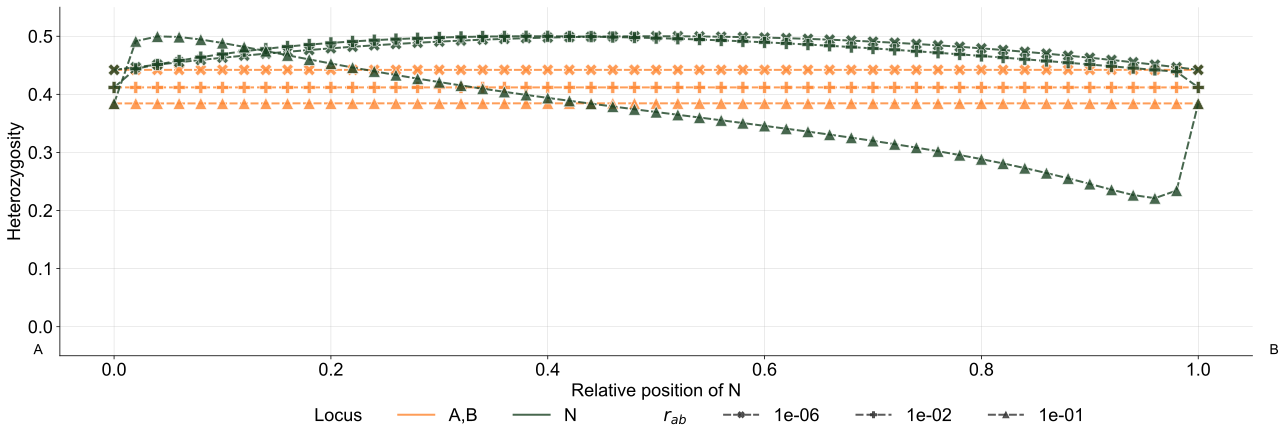

In [756]:
plot_heterozygosity_dist_neutb_poster(haplo_freq,
                              max_gen,
                              get_selection_mat(overdom, epi_vec, neutb=True),
                              [0,0],
                              rab,
#                              allelelist=['N'],
#                              title = ' \n ',
                              width=18,
                              height=6,
                              npoints=50, legendbelow=True,
                              filename = '../Fig/3_loci/fig4B_BN.svg')

### Claudia's ppt

#### Overdominance

In [74]:
rab = [1e-6,1e-2, 1e-1]
overdominance = [0.02,0.02]

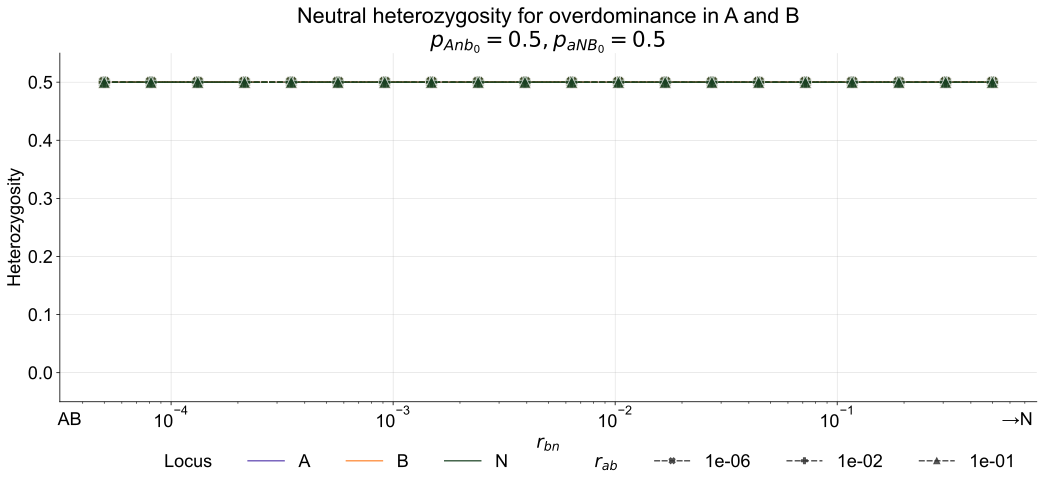

In [56]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              1000,
                              get_selection_mat(overdominance, [0,0,0,0]),
                              [0,0],
                              rab,
                              allelelist=['A', 'B', 'N'],
                              title = 'Neutral heterozygosity for overdominance in A and B\n$p_{Anb_0}=0.5, p_{aNB_0}=0.5$',
                              width=15,
                              height=6,
                              legendbelow=True,
                              filename = '../Fig/3_loci/overdominance_pA0.5pB0.5_ABN.svg')

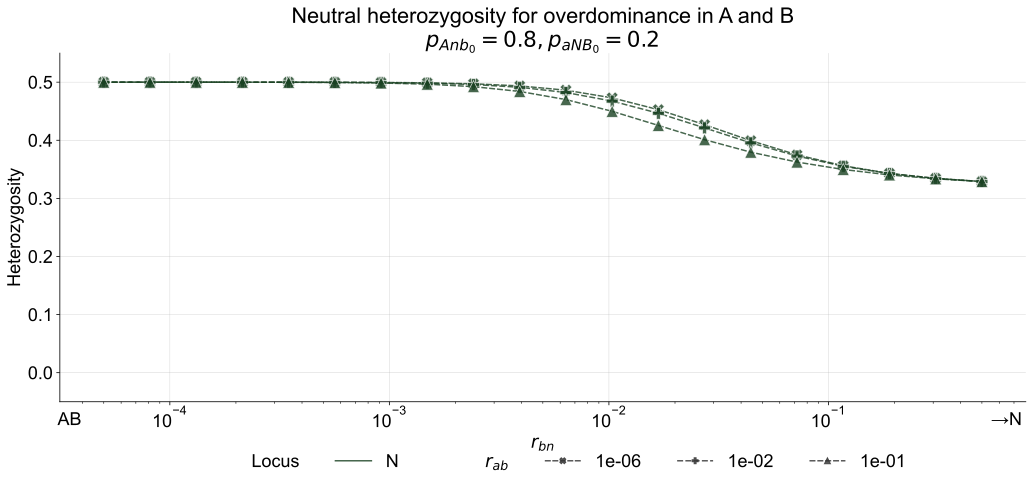

In [59]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat(overdominance, [0,0,0,0]),
                              [0,0],
                              rab,
                              allelelist=['N'],
                              title = 'Neutral heterozygosity for overdominance in A and B\n$p_{Anb_0}=0.8, p_{aNB_0}=0.2$',
                              width=15,
                              height=6,
                              legendbelow=True,
                              filename = '../Fig/3_loci/overdominance_pA0.8pB0.2_N.svg')

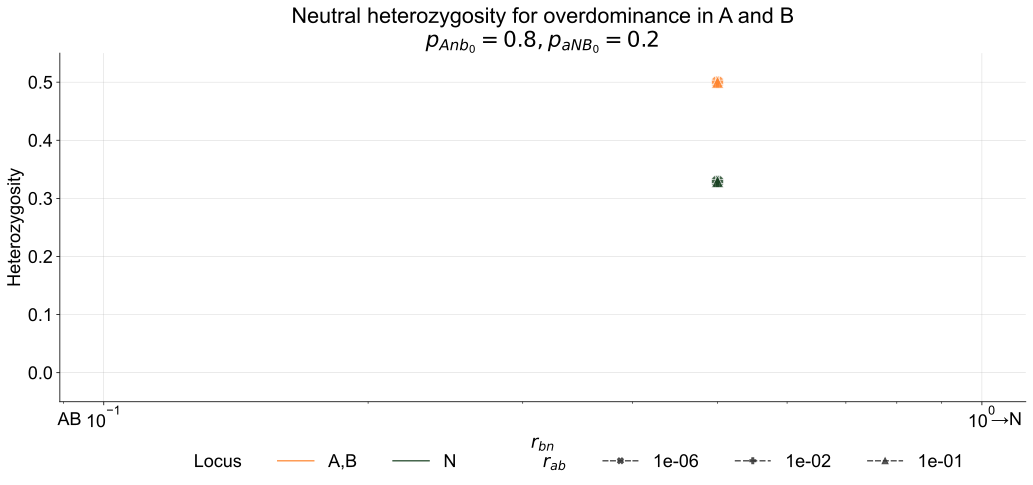

In [62]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat(overdominance, [0,0,0,0]),
                              [0,0],
                              rab,
                              allelelist=['B','N'],
                              title = 'Neutral heterozygosity for overdominance in A and B\n$p_{Anb_0}=0.8, p_{aNB_0}=0.2$',
                              width=15,
                              height=6,
                              legendbelow=True,
                              rmin=0, rmax=0, steps=1,
                              filename = '../Fig/3_loci/overdominance_legend.svg')

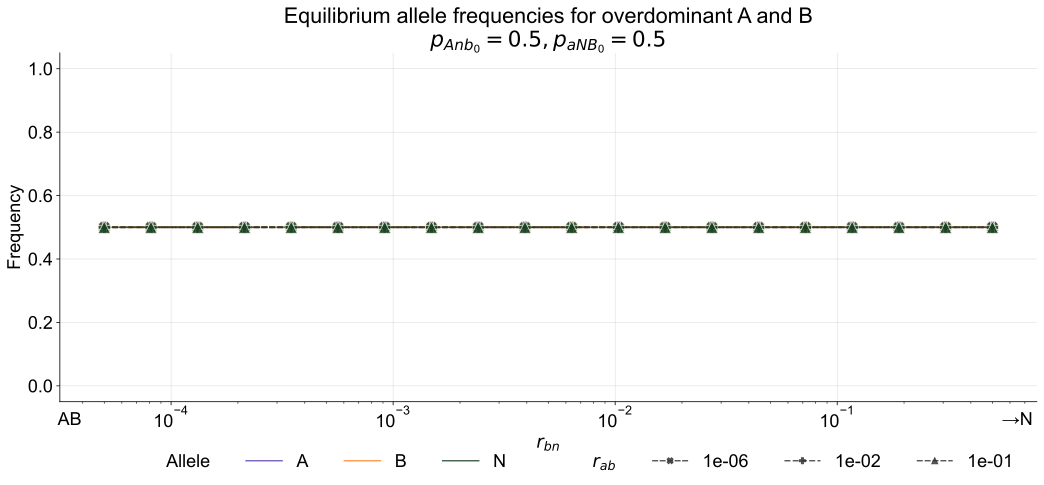

In [68]:
##### As freq

haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              1000,
                              get_selection_mat(overdominance, [0,0,0,0]),
                              [0,0],
                              rab,
                              allelelist=['A', 'B', 'N'],
                              title = 'Equilibrium allele frequencies for overdominant A and B\n$p_{Anb_0}=0.5, p_{aNB_0}=0.5$',
                              width=15,
                              height=6,
                              legendbelow=True,
                              yaxis='freq',
                              filename = '../Fig/3_loci/overdominance_freq_pA0.5pB0.5_ABN.svg')

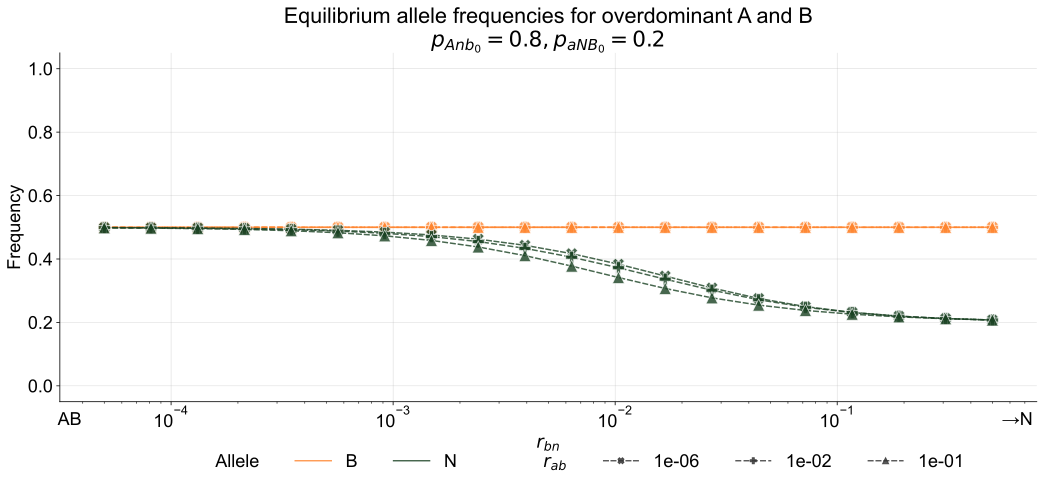

In [71]:
##### As freq

haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat(overdominance, [0,0,0,0]),
                              [0,0],
                              rab,
                              allelelist=['B', 'N'],
                              title = 'Equilibrium allele frequencies for overdominant A and B\n$p_{Anb_0}=0.8, p_{aNB_0}=0.2$',
                              width=15,
                              height=6,
                              legendbelow=True,
                              yaxis='freq',
                              filename = '../Fig/3_loci/overdominance_freq_pA0.8pB0.2_ABN.svg')

#### Codominant DMIs

In [75]:
rab = [1e-6,1e-2, 1e-1]
gamma = 0.02
codominant_dmis = [gamma/2,gamma,gamma,2*gamma]
recessive_dmis = [0,gamma,gamma,2*gamma]

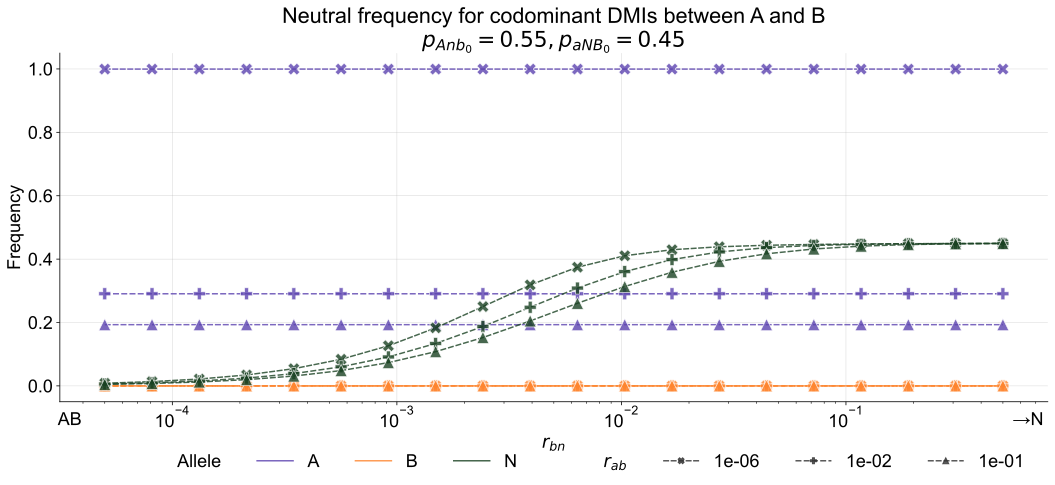

In [78]:
haplo_freq = [0. , 0.55, 0. , 0. , 0. , 0. , 0.45, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], codominant_dmis),
                              [0,0],
                              rab,
                              allelelist=['A','B','N'],
                              title = 'Neutral frequency for codominant DMIs between A and B\n$p_{Anb_0}=0.55, p_{aNB_0}=0.45$',
                              width=15,
                              height=6,
                              yaxis='freq',
                              legendbelow=True,
                              filename = '../Fig/3_loci/codominantDMIs_freq_pA0.55pB0.45_ABN.svg')

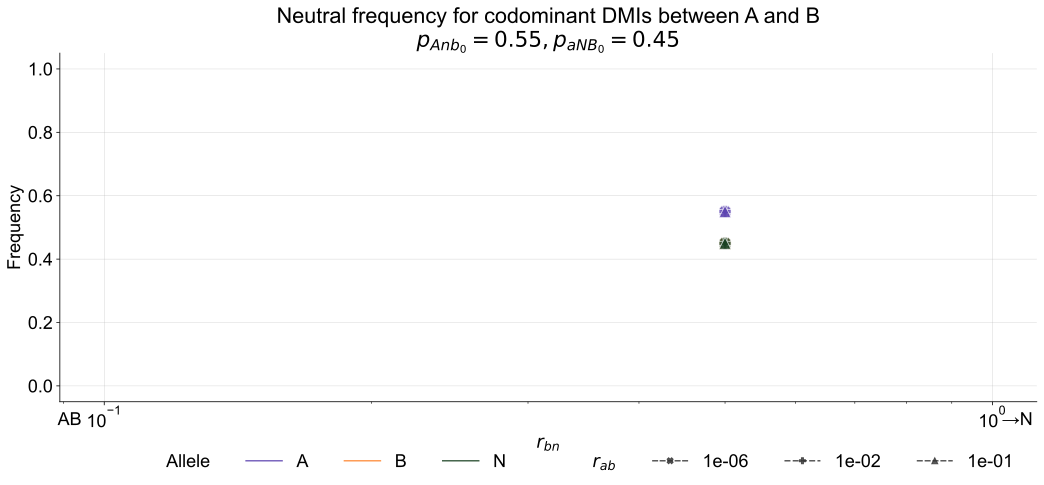

In [81]:
haplo_freq = [0. , 0.55, 0. , 0. , 0. , 0. , 0.45, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              0,
                              get_selection_mat([0,0], codominant_dmis),
                              [0,0],
                              rab,
                              allelelist=['A','B','N'],
                              title = 'Neutral frequency for codominant DMIs between A and B\n$p_{Anb_0}=0.55, p_{aNB_0}=0.45$',
                              width=15,
                              height=6,
                              yaxis='freq',
                              legendbelow=True,
                              rmin=0, rmax=0, steps=1,       
                              filename = '../Fig/3_loci/codominantDMIs_freq_pA0.55pB0.45_ABN_init.svg')

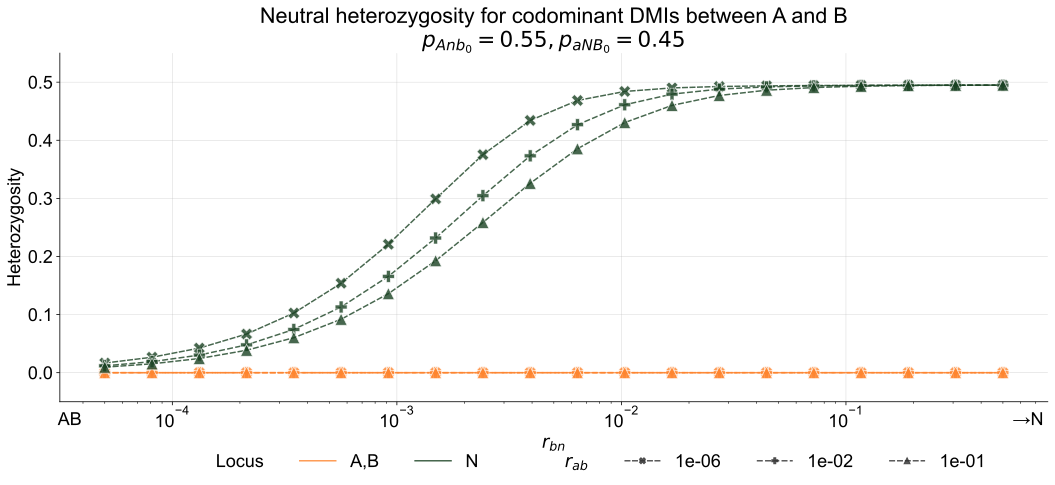

In [80]:
haplo_freq = [0. , 0.55, 0. , 0. , 0. , 0. , 0.45, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], codominant_dmis),
                              [0,0],
                              rab,
                              allelelist=['B', 'N'],
                              title = 'Neutral heterozygosity for codominant DMIs between A and B\n$p_{Anb_0}=0.55, p_{aNB_0}=0.45$',
                              width=15,
                              height=6,
                              legendbelow=True,
                              filename = '../Fig/3_loci/PPT_codominantDMIs_pA0.55pB0.45_ABN.svg')

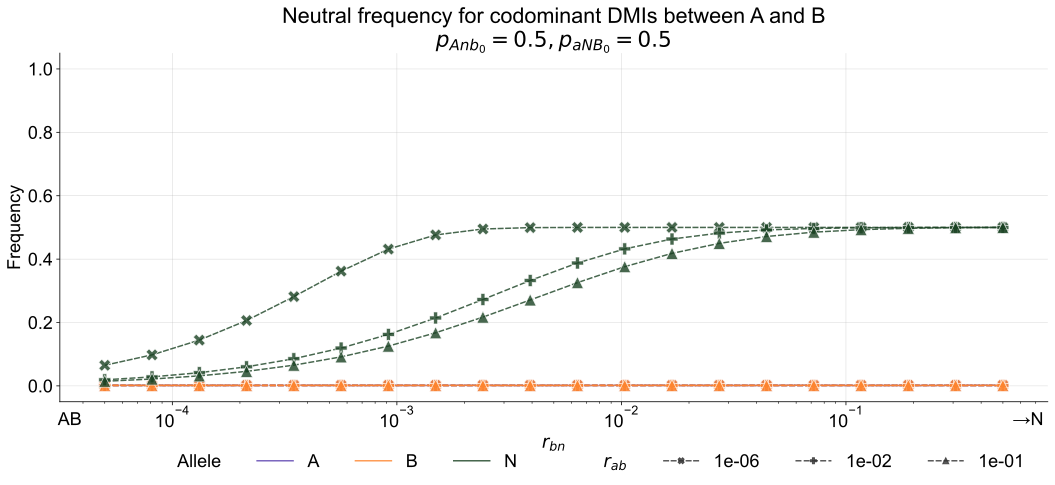

In [83]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], codominant_dmis),
                              [0,0],
                              rab,
                              allelelist=['A','B','N'],
                              title = 'Neutral frequency for codominant DMIs between A and B\n$p_{Anb_0}=0.5, p_{aNB_0}=0.5$',
                              width=15,
                              height=6,
                              yaxis='freq',
                              legendbelow=True,
                              filename = '../Fig/3_loci/codominantDMIs_freq_pA0.5pB0.5_ABN.svg')

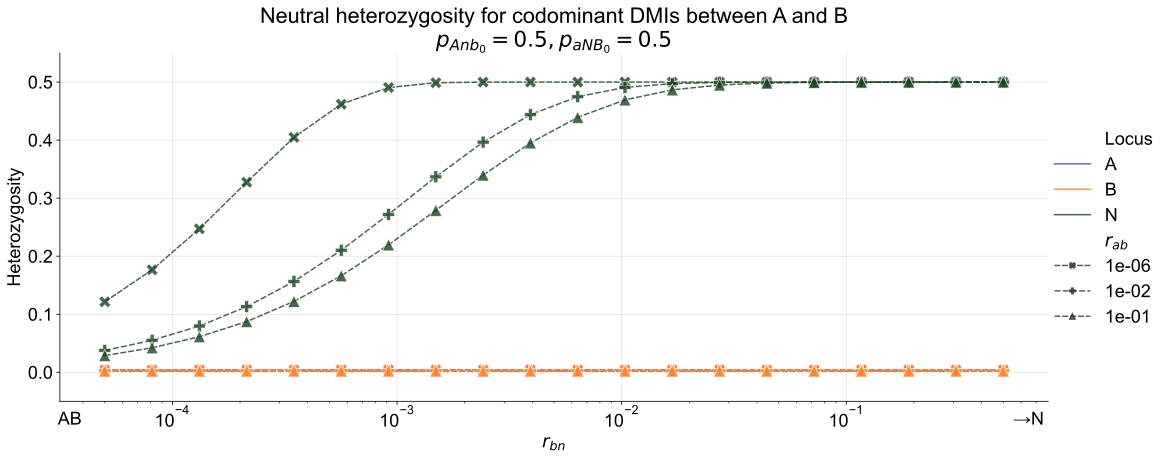

In [82]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], codominant_dmis),
                              [0,0],
                              rab,
                              allelelist=['A', 'B', 'N'],
                              title = 'Neutral heterozygosity for codominant DMIs between A and B\n$p_{Anb_0}=0.5, p_{aNB_0}=0.5$',
                              width=15,
                              height=6,
                              filename = '../Fig/3_loci/PPT_codominantDMIs_pA0.5pB0.5_ABN.svg')

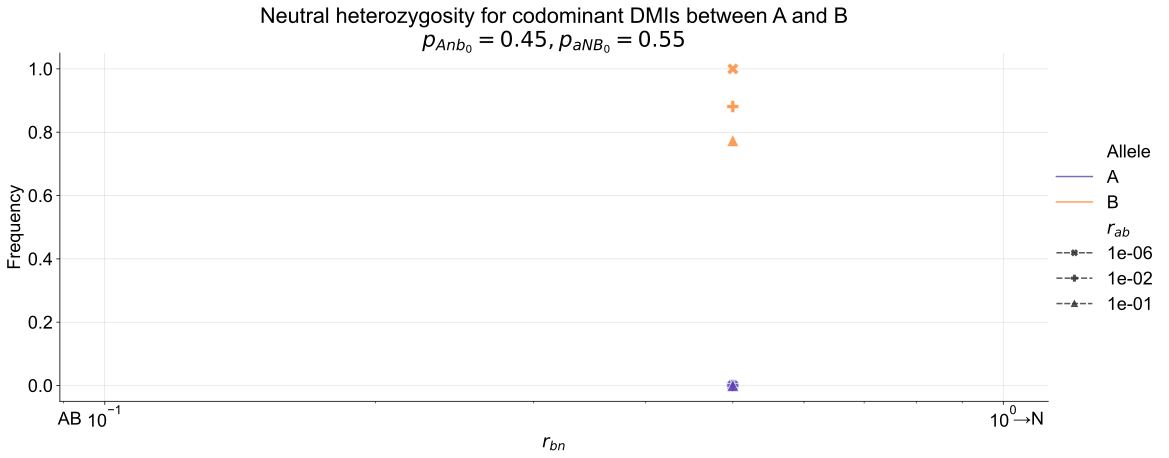

In [789]:
haplo_freq = [0. , 0.2, 0. , 0. , 0. , 0. , 0.8, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], codominant_dmis),
                              [0,0],
                              rab,
                              allelelist=['A', 'B'],
                              title = 'Allele frequency for codominant DMIs between A and B\n$p_{Anb_0}=0.45, p_{aNB_0}=0.55$',
                              width=15,
                              height=6,
                              yaxis="freq", rmin=0, rmax=0, steps=1,
                              filename = '../Fig/3_loci/PPT_codominantDMIs_pA0.2pB0.8_CUT.svg')

#### Recessive DMIs

In [84]:
rab = [1e-6,1e-2, 1e-1]
gamma = 0.02
codominant_dmis = [gamma/2,gamma,gamma,2*gamma]
recessive_dmis = [0,gamma,gamma,2*gamma]

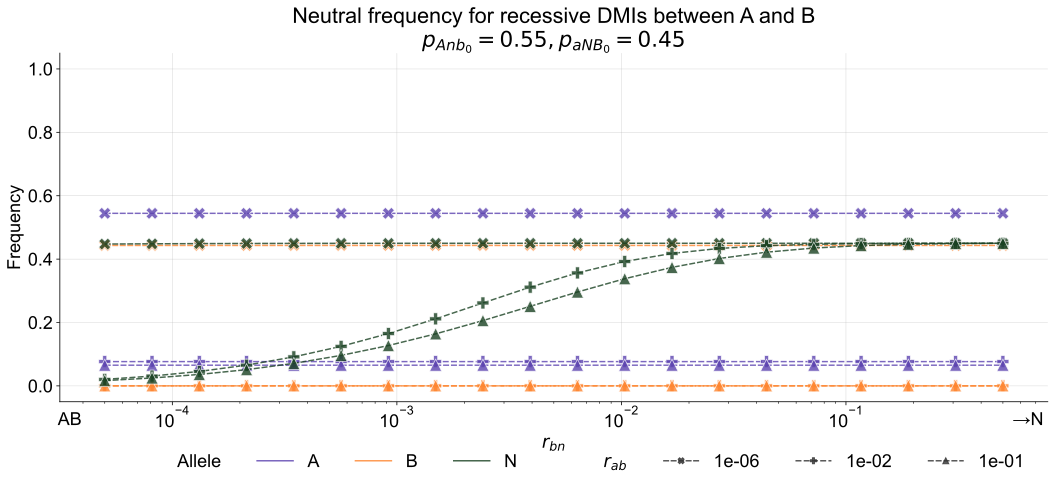

In [95]:
haplo_freq = [0. , 0.55, 0. , 0. , 0. , 0. , 0.45, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], recessive_dmis),
                              [0,0],
                              rab,
                              allelelist=['A','B','N'],
                              title = 'Neutral frequency for recessive DMIs between A and B\n$p_{Anb_0}=0.55, p_{aNB_0}=0.45$',
                              width=15,
                              height=6,
                              yaxis='freq',
                              legendbelow=True,
                              filename = '../Fig/3_loci/recessiveDMIs_freq_pA0.55pB0.45_ABN.svg')

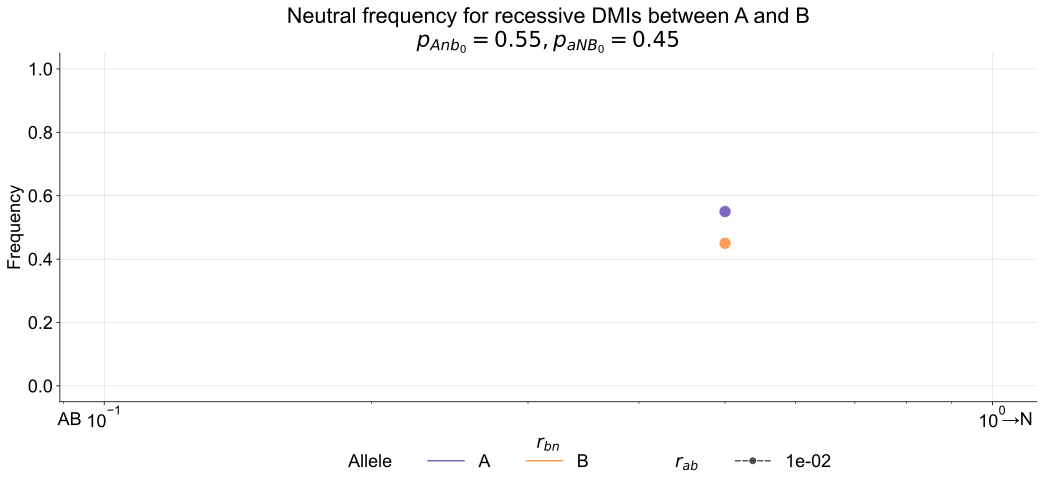

In [92]:
haplo_freq = [0. , 0.55, 0. , 0. , 0. , 0. , 0.45, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              0,
                              get_selection_mat([0,0], recessive_dmis),
                              [0,0],
                              [0.01],
                              allelelist=['A','B'],
                              title = 'Neutral frequency for recessive DMIs between A and B\n$p_{Anb_0}=0.55, p_{aNB_0}=0.45$',
                              width=15,
                              height=6,
                              yaxis='freq',
                              legendbelow=True,
                              rmin=0, rmax=0, steps=1,
                              filename = '../Fig/3_loci/recessiveDMIs_freq_pA0.55pB0.45_ABN_init.svg')

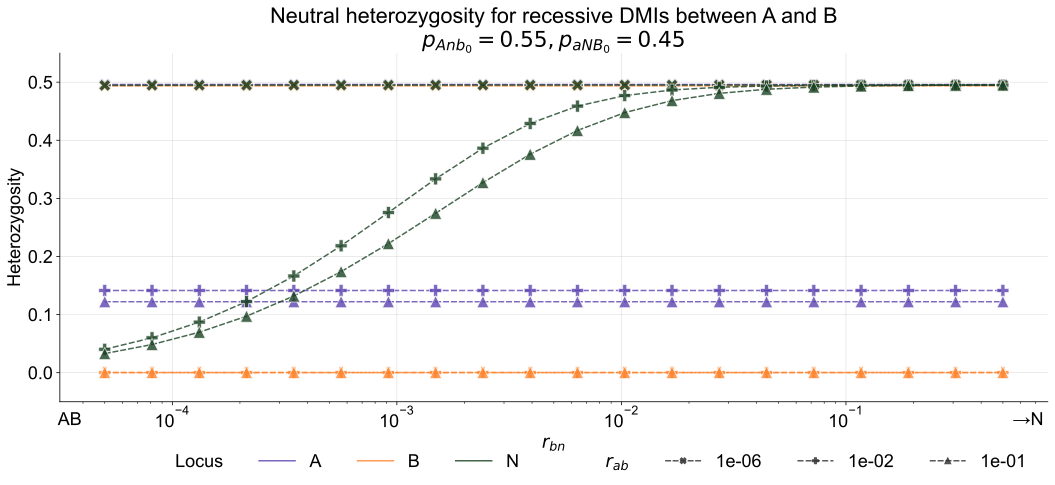

In [96]:
haplo_freq = [0. , 0.55, 0. , 0. , 0. , 0. , 0.45, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], recessive_dmis),
                              [0,0],
                              rab,
                              allelelist=['A','B', 'N'],
                              title = 'Neutral heterozygosity for recessive DMIs between A and B\n$p_{Anb_0}=0.55, p_{aNB_0}=0.45$',
                              width=15,
                              height=6,
                              legendbelow=True,
                              filename = '../Fig/3_loci/PPT_recessiveDMIs_pA0.55pB0.45_ABN.svg')

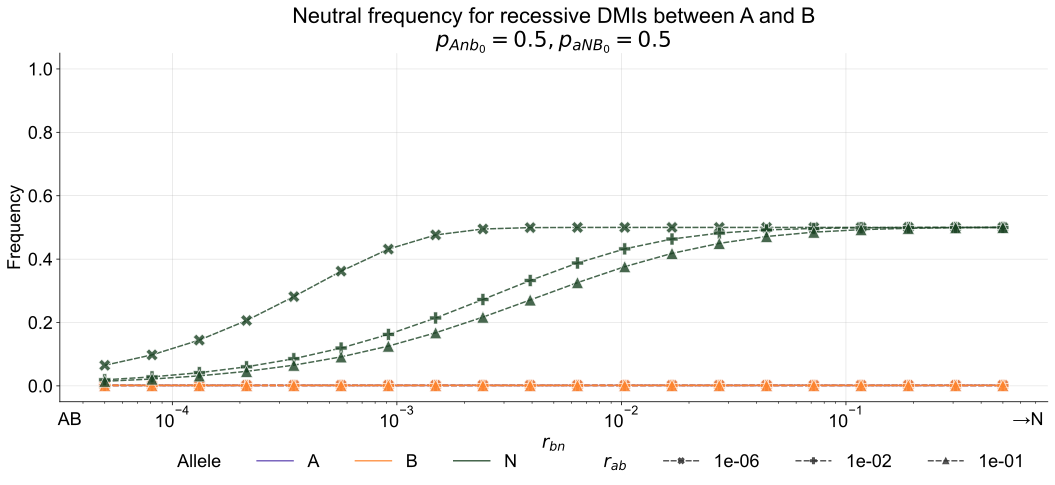

In [88]:
#run here
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], codominant_dmis),
                              [0,0],
                              rab,
                              allelelist=['A','B','N'],
                              title = 'Neutral frequency for recessive DMIs between A and B\n$p_{Anb_0}=0.5, p_{aNB_0}=0.5$',
                              width=15,
                              height=6,
                              yaxis='freq',
                              legendbelow=True,
                              filename = '../Fig/3_loci/recessiveDMIs_freq_pA0.5pB0.5_ABN.svg')

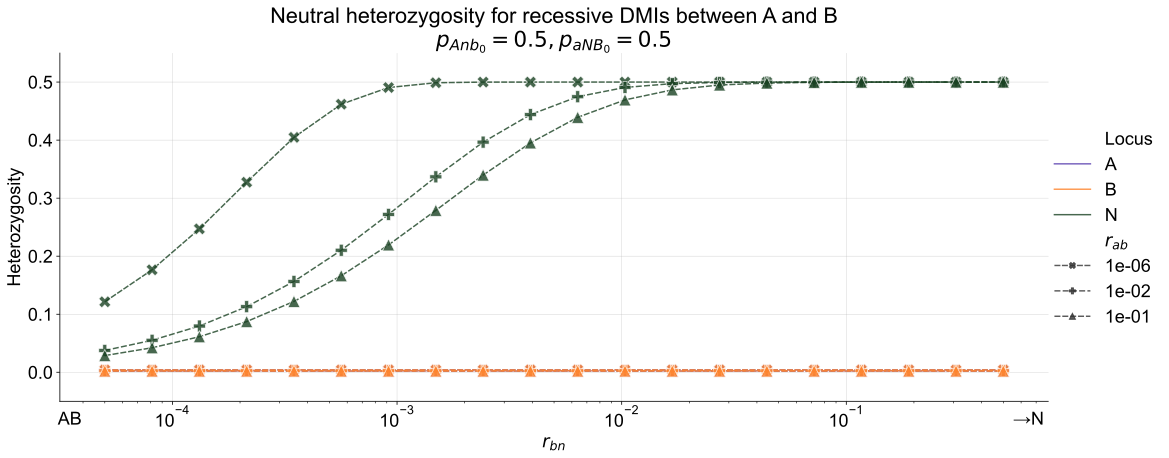

In [89]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], codominant_dmis),
                              [0,0],
                              rab,
                              allelelist=['A', 'B', 'N'],
                              title = 'Neutral heterozygosity for recessive DMIs between A and B\n$p_{Anb_0}=0.5, p_{aNB_0}=0.5$',
                              width=15,
                              height=6,
                              filename = '../Fig/3_loci/PPT_recessiveDMIs_pA0.5pB0.5_ABN.svg')

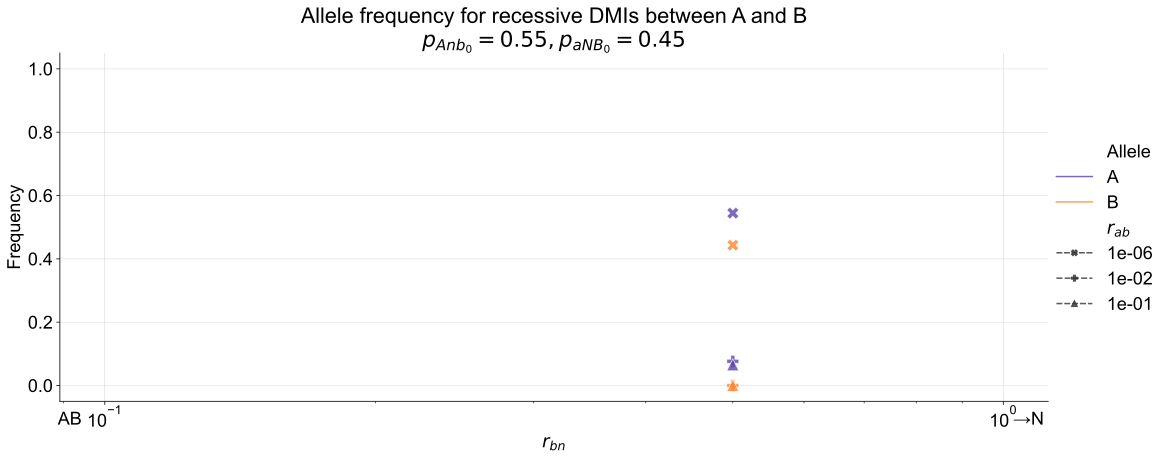

In [94]:
haplo_freq = [0. , 0.55, 0. , 0. , 0. , 0. , 0.45, 0.]
df = plot_heterozygosity_dist_poster(haplo_freq,
                              max_gen,
                              get_selection_mat([0,0], recessive_dmis),
                              [0,0],
                              rab,
                              allelelist=['A', 'B'],
                              title = 'Allele frequency for recessive DMIs between A and B\n$p_{Anb_0}=0.55, p_{aNB_0}=0.45$',
                              width=15,
                              height=6,
                              yaxis="freq", rmin=0, rmax=0, steps=1,
                              filename = '../Fig/3_loci/PPT_recessiveDMIs_pA0.55pB0.45_CUT.svg')

#### END 

In [70]:
plt.rcParams.update({'font.size': 10}) ## Return to orig

## Updated

### ESEB CB ppt

#### Overdominance

In [42]:
rab = [1e-6,1e-2, 1e-1]
overdominance = [0.02,0.02]
max_gen = 50000
epi_vec = [0.01,0.02,0.02,0.04]
mig_vec = [0,0]
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
res_od_05 = simulate_populations(haplo_freq, 
                         max_gen,
                         get_selection_mat(overdominance, [0,0,0,0]),
                         mig_vec,
                         rab,
                         outtype='alleles', rmin=-5, rmax=0, steps=20)

/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


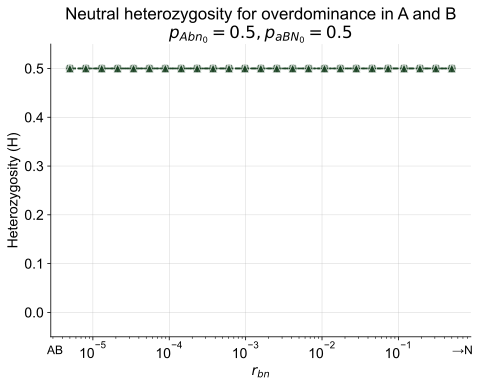

1

In [43]:
plot_heterozygosity_new(res_od_05,
                        yaxis ='het',
                        allelelist = ['N'],
                        title = 'Neutral heterozygosity for overdominance in A and B\n$p_{Abn_0}=0.5, p_{aBN_0}=0.5$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none",
                        filename = '../Fig/3_loci/N_overdominance_pA0.5pB0.5.svg')

/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


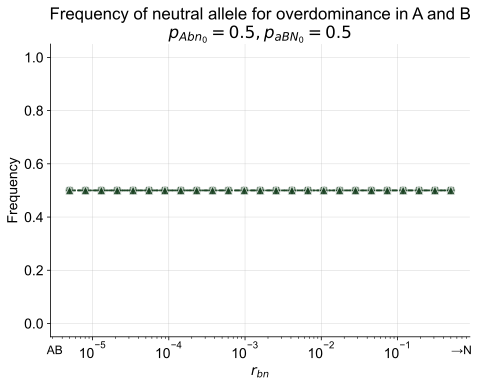

1

In [44]:
plot_heterozygosity_new(res_od_05,
                        yaxis ='freq',
                        allelelist = ['N'],
                        title = 'Frequency of neutral allele for overdominance in A and B\n$p_{Abn_0}=0.5, p_{aBN_0}=0.5$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none",
                        filename = '../Fig/3_loci/N_overdominance_freq_pA0.5pB0.5.svg')

In [45]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
res_od_08 = simulate_populations(haplo_freq, 
                         max_gen,
                         get_selection_mat(overdominance, [0,0,0,0]),
                         mig_vec,
                         rab,
                         outtype='alleles', rmin=-5, rmax=0, steps=20)
res_od_08 = res_od_08[0] # Get first dataframe

/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


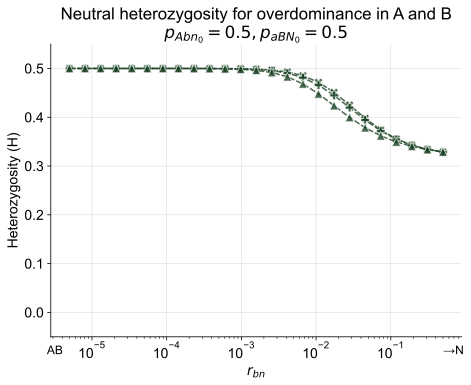

1

In [108]:
plot_heterozygosity_new(res_od_08,
                        yaxis ='het',
                        allelelist = ['N'],
                        title = 'Neutral heterozygosity for overdominance in A and B\n$p_{Abn_0}=0.5, p_{aBN_0}=0.5$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none",
                        filename = '../Fig/3_loci/N_overdominance_pA0.8pB0.2_N.svg')

/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


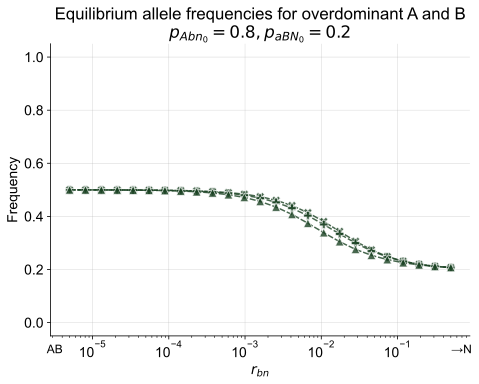

1

In [109]:
plot_heterozygosity_new(res_od_08,
                        yaxis ='freq',
                        allelelist = ['N'],
                        title = 'Equilibrium allele frequencies for overdominant A and B\n$p_{Abn_0}=0.8, p_{aBN_0}=0.2$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none",
                        filename = '../Fig/3_loci/N_overdominance_freq_pA0.8pB0.2_N.svg')

/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


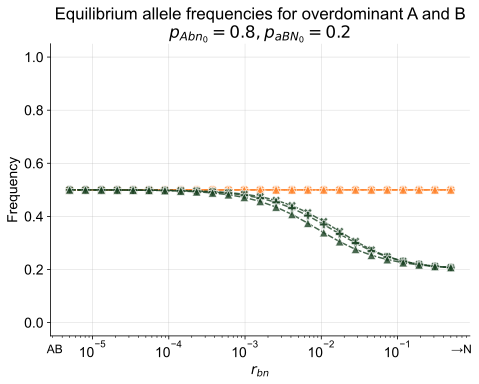

1

In [110]:
plot_heterozygosity_new(res_od_08,
                        yaxis ='freq',
                        allelelist = ['B','N'],
                        title = 'Equilibrium allele frequencies for overdominant A and B\n$p_{Abn_0}=0.8, p_{aBN_0}=0.2$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none",
                        filename = '../Fig/3_loci/N_overdominance_freq_pA0.8pB0.2_BN.svg')

/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


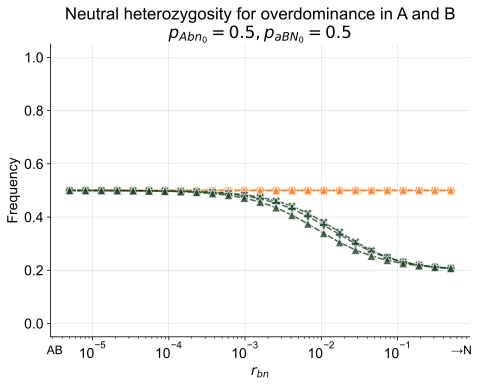

1

In [111]:
plot_heterozygosity_new(res_od_08,
                        yaxis ='freq',
                        allelelist = ['B','N'],
                        title = 'Neutral heterozygosity for overdominance in A and B\n$p_{Abn_0}=0.5, p_{aBN_0}=0.5$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none",
                        filename = '../Fig/3_loci/N_overdominance_freq_pA0.8pB0.2_BN.svg')

#### Codominant DMIs

In [372]:
rab = [1e-6,1e-2, 1e-1]
gamma = 0.02
codominant_dmis = [gamma/2,gamma,gamma,2*gamma]
recessive_dmis = [0,gamma*2,gamma*2,4*gamma]
max_gen = 50000
mig_vec = [0,0]
haplo_freq = [0. , 0.55, 0. , 0. , 0. , 0. , 0.45, 0.]

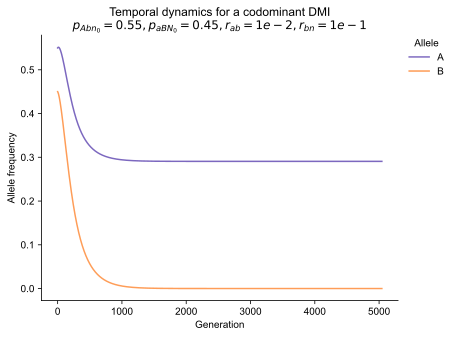

[np.float64(0.29065171869381007),
 np.float64(7.563426300969793e-11),
 np.float64(0.44573619769651984)]

In [373]:
# BACK HERE
plot_dyn_freqs(haplo_freq,
               max_gen, 
               get_selection_mat([0,0], codominant_dmis),
               mig_vec, 
               [1e-2,1*10**(-1)],
               exclude=['N'],
               title="Temporal dynamics for a codominant DMI\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45, r_{ab}=1e-2,r_{bn}=1e-1$",
               filename="../Fig/3_loci/dynamics_codom_rab1e-2_rbn1e-1.svg")

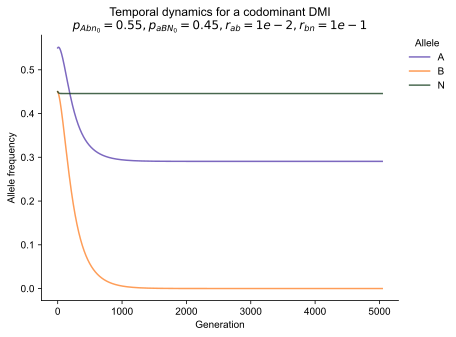

[np.float64(0.29065171869381007),
 np.float64(7.563426300969793e-11),
 np.float64(0.44573619769651984)]

In [375]:
plot_dyn_freqs(haplo_freq,
               max_gen, 
               get_selection_mat([0,0], codominant_dmis),
               mig_vec, 
               [1e-2,1*10**(-1)],
               title="Temporal dynamics for a codominant DMI\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45, r_{ab}=1e-2,r_{bn}=1e-1$",
               filename="../Fig/3_loci/dynamics_codom_rab1e-2_rbn1e-1_ABN.svg")

In [52]:
res_codom_055 = simulate_populations(haplo_freq, 
                         max_gen,
                         get_selection_mat([0,0], codominant_dmis),
                         mig_vec,
                         rab,
                         outtype='alleles', rmin=-4, rmax=0, steps=20)

In [53]:
res_codom_055.head()

,r_ab,r_bc,allele,freq,het
0,1e-06,0.000005,A,9.999892e-01,2.155449e-05
1,1e-06,0.000005,B,1.587391e-11,3.174794e-11
2,1e-06,0.000005,N,4.657793e-05,9.315152e-05
3,1e-06,0.000008,A,9.999892e-01,2.155449e-05
4,1e-06,0.000008,B,1.587391e-11,3.174794e-11


/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


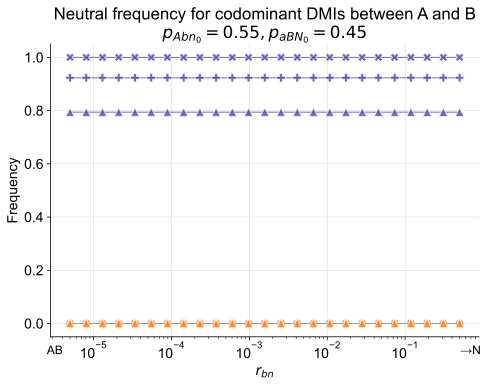

1

In [54]:
plot_heterozygosity_new(res_codom_055,
                        yaxis ='freq',
                        allelelist = ['A', 'B'],
                        title = 'Neutral frequency for codominant DMIs between A and B\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none",
                        dasheslist=[(3,0),(3,0),(3,0)], linewidth=1,
                        filename = '../Fig/3_loci/N_codominantDMIs_freq_pA0.55pB0.45_AB.svg')

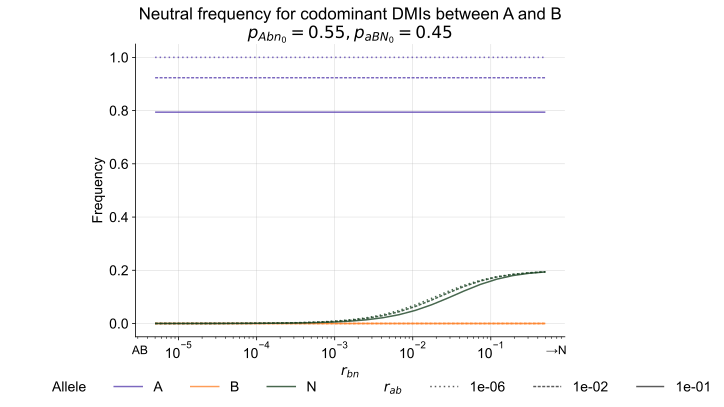

1

In [55]:
plot_heterozygosity_new(res_codom_055,
                        yaxis ='freq',
                        allelelist = ['A', 'B', 'N'],
                        title = 'Neutral frequency for codominant DMIs between A and B\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45$',
                        width=7,
                        height=5, fontsize=14, markersize=0, legendpos="below",
                        dasheslist=[(1,2),(2,1),(3,0)],
                        filename = '../Fig/3_loci/N_codominantDMIs_freq_pA0.55pB0.45_AB_dashed.svg')

/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


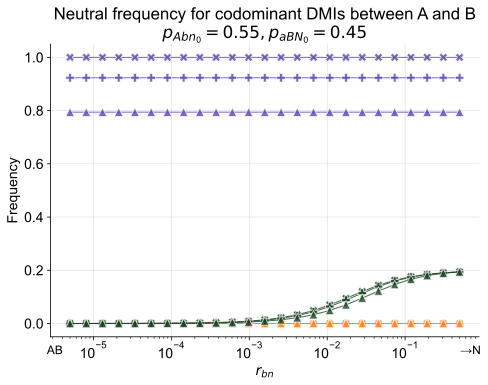

1

In [56]:
plot_heterozygosity_new(res_codom_055,
                        yaxis ='freq',
                        allelelist = ['A', 'B', 'N'],
                        title = 'Neutral frequency for codominant DMIs between A and B\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none", linewidth=1,
                        dasheslist=[(3,0),(3,0),(3,0)],
                        filename = '../Fig/3_loci/N_codominantDMIs_freq_pA0.55pB0.45_ABN.svg')

/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


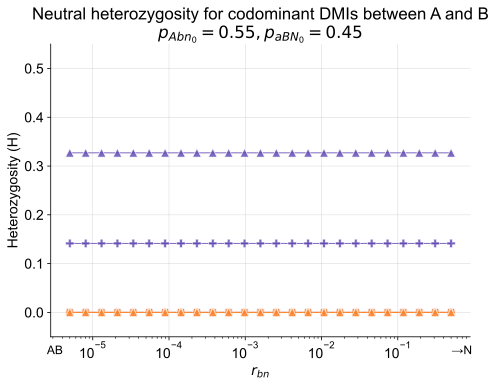

1

In [57]:
plot_heterozygosity_new(res_codom_055,
                        yaxis ='het',
                        allelelist = ['A','B'],
                        title = 'Neutral heterozygosity for codominant DMIs between A and B\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none", linewidth=1,
                        dasheslist=[(3,0),(3,0),(3,0)],
                        filename = '../Fig/3_loci/N_PPT_codominantDMIs_pA0.55pB0.45_AB.svg')

/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


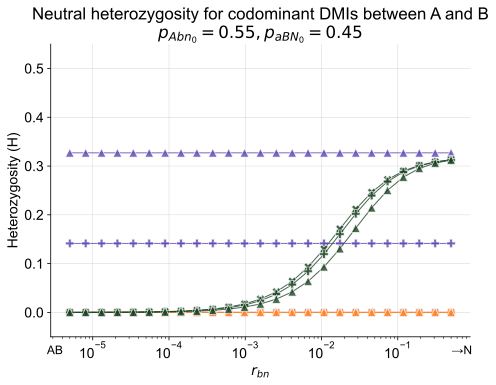

1

In [58]:
plot_heterozygosity_new(res_codom_055,
                        yaxis ='het',
                        allelelist = ['A','B', 'N'],
                        title = 'Neutral heterozygosity for codominant DMIs between A and B\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none", linewidth=1,
                        dasheslist=[(3,0),(3,0),(3,0)],
                        filename = '../Fig/3_loci/N_PPT_codominantDMIs_pA0.55pB0.45_ABN.svg')

#### Recessive DMIs

In [59]:
rab = [1e-3,1e-2, 1e-1]
gamma = 0.02
codominant_dmis = [gamma/2,gamma,gamma,2*gamma]
recessive_dmis = [0,gamma,gamma,2*gamma]
haplo_freq = [0. , 0.55, 0. , 0. , 0. , 0. , 0.45, 0.]

In [60]:
res_recess_055 = simulate_populations(haplo_freq, 
                         max_gen*2,
                         get_selection_mat([0,0], recessive_dmis),
                         mig_vec,
                         rab,
                         outtype='alleles', rmin=-4, rmax=0, steps=20)

##### Plots

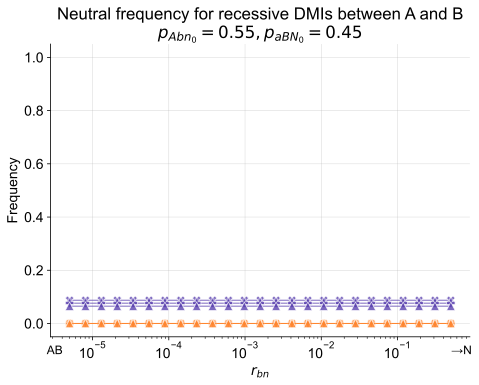

1

In [382]:
plot_heterozygosity_new(res_recess_055,
                        yaxis ='freq',
                        allelelist = ['A', 'B'],
                        title = 'Neutral frequency for recessive DMIs between A and B\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none", linewidth=1,
                        dasheslist=[(3,0),(3,0),(3,0)],
                        filename = '../Fig/3_loci/N_recessiveDMIs_freq_pA0.55pB0.45_AB.svg')



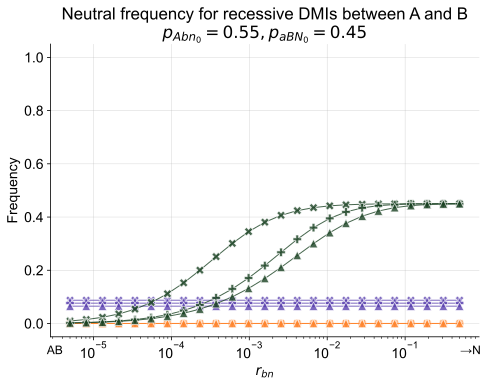

1

In [391]:
plot_heterozygosity_new(res_recess_055,
                        yaxis ='freq',
                        allelelist = ['A', 'B', 'N'],
                        title = 'Neutral frequency for recessive DMIs between A and B\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none", linewidth=1,
                        dasheslist=[(3,0),(3,0),(3,0)],
                        filename = '../Fig/3_loci/N_recessiveDMIs_freq_pA0.55pB0.45_ABN.svg')



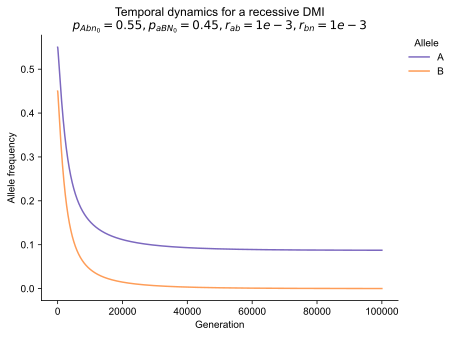

[np.float64(0.08736705349659224),
 np.float64(0.00010018437021796889),
 np.float64(0.34691839650600526)]

In [385]:
# BACK HERE
plot_dyn_freqs(haplo_freq,
               max_gen*2, 
               get_selection_mat([0,0], recessive_dmis),
               mig_vec, 
               [1e-3,1*10**(-3)],
               exclude=['N'],
               title="Temporal dynamics for a recessive DMI\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45, r_{ab}=1e-3,r_{bn}=1e-3$",
               filename="../Fig/3_loci/dynamics_recess_rab1e-2_rbn1e-1.svg")

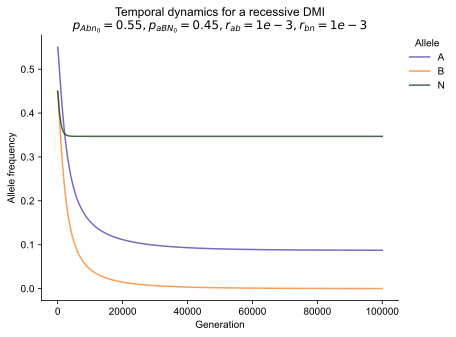

[np.float64(0.08736705349659224),
 np.float64(0.00010018437021796889),
 np.float64(0.34691839650600526)]

In [386]:
# BACK HERE
plot_dyn_freqs(haplo_freq,
               max_gen*2, 
               get_selection_mat([0,0], recessive_dmis),
               mig_vec, 
               [1e-3,1*10**(-3)],
               title="Temporal dynamics for a recessive DMI\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45, r_{ab}=1e-3,r_{bn}=1e-3$",
               filename="../Fig/3_loci/dynamics_recess_rab1e-2_rbn1e-1_ABN.svg")

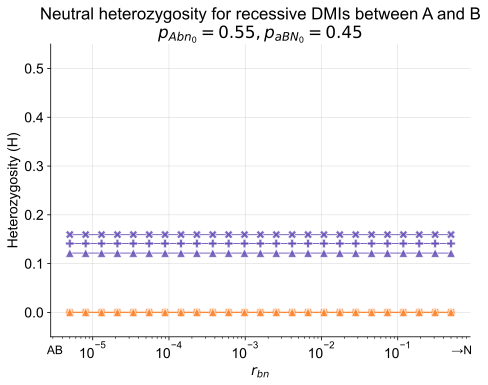

1

In [388]:
plot_heterozygosity_new(res_recess_055,
                        yaxis ='het',
                        allelelist = ['A', 'B'],
                        title = 'Neutral heterozygosity for recessive DMIs between A and B\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none", linewidth=1,
                        dasheslist=[(3,0),(3,0),(3,0)],
                        filename = '../Fig/3_loci/N_recessiveDMIs_het_pA0.55pB0.45_AB.svg')



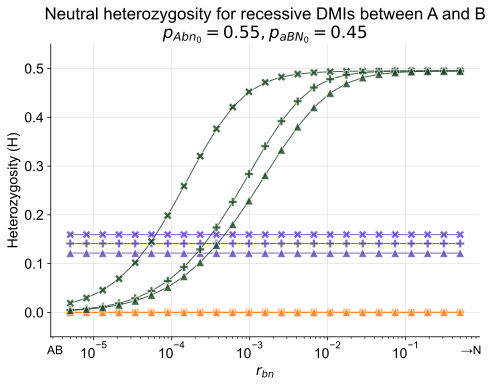

1

In [392]:
plot_heterozygosity_new(res_recess_055,
                        yaxis ='het',
                        allelelist = ['A', 'B', 'N'],
                        title = 'Neutral heterozygosity for recessive DMIs between A and B\n$p_{Abn_0}=0.55, p_{aBN_0}=0.45$',
                        width=7,
                        height=5, fontsize=14, markersize=8.5, legendpos="none", linewidth=1,
                        dasheslist=[(3,0),(3,0),(3,0)],
                        filename = '../Fig/3_loci/N_recessiveDMIs_het_pA0.55pB0.45_ABN.svg')



### DMIs + Heterosis

In [151]:
max_gen = 50000
overdom = [0.03,0.03]
epi_vec = [0.03,0.06,0.06,0.12]
rab = [1e-6,1e-2,1e-1]
mig_vec = [0,0]
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]

In [152]:
resall = simulate_populations(haplo_freq, 
                         max_gen,
                         get_selection_mat(overdom, epi_vec),
                         mig_vec,
                         rab,
                         outtype='alleles', rmin=-5, rmax=0, steps=25)

In [153]:
resall_allele = resall[0]
resall_haplo = resall[1]

In [154]:
resall_neutb = simulate_populations(haplo_freq, 
                         max_gen,
                         get_selection_mat(overdom, epi_vec, neutb=True),
                         mig_vec,
                         rab,
                         neutb=True,
                         outtype='alleles', npoints=25)


In [155]:
resall_neutb_allele = resall_neutb[0]
resall_neutb_haplo = resall_neutb[1]

In [156]:
resall_allele.to_csv('../Data/results_ABN_g=2a=_0.06_pa0=0.8_pb0=0.2.csv')
resall_neutb_allele.to_csv('../Data/results_ANB_g=2a=_0.06_pa0=0.8_pb0=0.2.csv')
resall_haplo.to_csv('../Data/results_ABN_g=2a=_0.06_pa0=0.8_pb0=0.2_haplotypes.csv')
resall_neutb_haplo.to_csv('../Data/results_ANB_g=2a=_0.06_pa0=0.8_pb0=0.2_haplotypes.csv')

##### Plots

/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


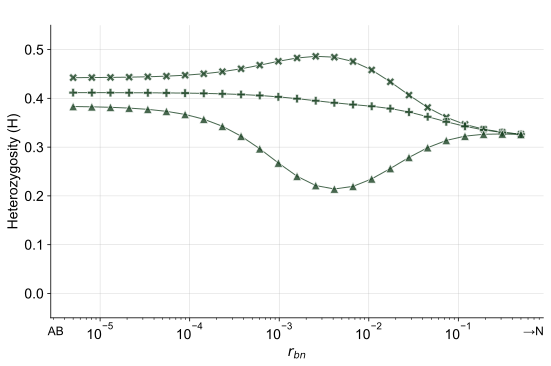

1

In [119]:
plot_heterozygosity_new(resall_allele,
                        yaxis ='het',
                        allelelist = ['N'],
                        title = ' ',
                        width=8,
                        height=5, fontsize=14, markersize=8.5, legendpos="none", linewidth=1,
                        dasheslist=[(3,0),(3,0),(3,0)],
                        filename = '../Fig/3_loci/N_DMIs_het_0.8_0.2.svg')



/var/folders/gv/df6632rx259gf7djjhn2xrsr0000gn/T/ipykernel_52529/2715916727.py:27: UserWarning: The markers list has more values (4) than needed (3), which may not be intended.
  figfreqs = sns.relplot(data=alleledf, x='pos' if neutb else 'r_bc', y=yaxis, hue='allele',


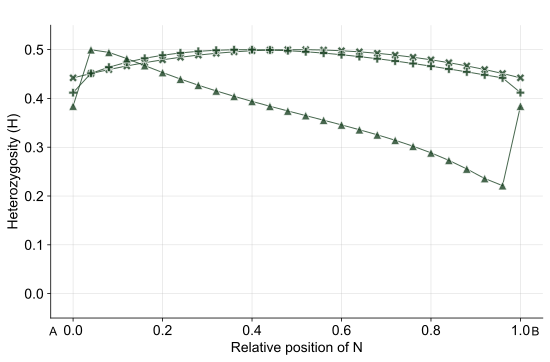

1

In [120]:
plot_heterozygosity_new(resall_neutb_allele,
                        yaxis ='het',
                        neutb=True,
                        allelelist = ['N'],
                        title = ' ',
                        width=8,
                        height=5, fontsize=14, markersize=8.5, legendpos="none", linewidth=1,
                        dasheslist=[(3,0),(3,0),(3,0)],
                        filename = '../Fig/3_loci/N_DMIs_het_0.8_0.2_neutb_N.svg')



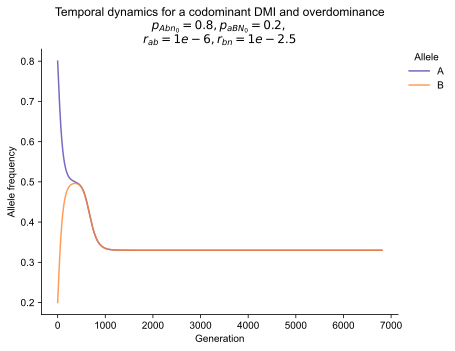

[np.float64(0.32992764939873126),
 np.float64(0.32992764939873104),
 np.float64(0.4168723864893023)]

In [121]:
# BACK HERE
plot_dyn_freqs(haplo_freq,
               max_gen, 
               get_selection_mat(overdom, epi_vec),
               mig_vec, 
               [1e-6,1*10**(-2.5)],
               exclude=['N'],
               title="Temporal dynamics for a codominant DMI and overdominance\n$p_{Abn_0}=0.8, p_{aBN_0}=0.2,$\n$r_{ab}=1e-6,r_{bn}=1e-2.5$",
               filename="../Fig/3_loci/dynamics_DMI_OD_rab1e-6_rbn1e-2.5_AB.svg")

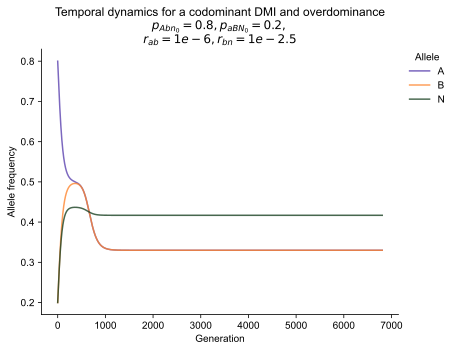

[np.float64(0.32992764939873126),
 np.float64(0.32992764939873104),
 np.float64(0.4168723864893023)]

In [122]:
# BACK HERE
plot_dyn_freqs(haplo_freq,
               max_gen, 
               get_selection_mat(overdom, epi_vec),
               mig_vec, 
               [1e-6,1*10**(-2.5)],
               title="Temporal dynamics for a codominant DMI and overdominance\n$p_{Abn_0}=0.8, p_{aBN_0}=0.2,$\n$r_{ab}=1e-6,r_{bn}=1e-2.5$",
               filename="../Fig/3_loci/dynamics_DMI_OD_rab1e-6_rbn1e-2.5_ABN.svg")

### Tests with LD

In [124]:
def get_ld(haplodf, neutb=False):
    # Gets LD of 
    #x1*x4 - x2*x3
    #x1 = bn
    #x2 = bN
    #x3 = Bn
    #x4 = BN
    
    #pBN - pBpN
    # pB = Bn + BN
    # pN = bN + BN
    if neutb:
        haplodf['x_bn'] = haplodf.Anb + haplodf.anb
        haplodf['x_bN'] = haplodf.ANb + haplodf.aNb
        haplodf['x_Bn'] = haplodf.AnB + haplodf.anB
        haplodf['x_BN'] = haplodf.ANB + haplodf.aNB
    else:
        haplodf['x_bn'] = haplodf.Abc + haplodf.abc
        haplodf['x_bN'] = haplodf.AbC + haplodf.abC
        haplodf['x_Bn'] = haplodf.ABc + haplodf.aBc
        haplodf['x_BN'] = haplodf.ABC + haplodf.aBC
    
    
    haplodf['ld_bn'] = (haplodf.x_bn*haplodf.x_BN) - (haplodf.x_bN*haplodf.x_Bn)
    
    return haplodf


In [144]:
lddf = get_ld(resall_haplo)
lddf_neutb = get_ld(resall_neutb_haplo, neutb=True)

In [138]:
lddf_neutb['rtot'] = lddf_neutb.r_ab + lddf_neutb.r_bc
lddf_neutb['pos'] = lddf_neutb.r_bc/lddf_neutb.rtot

In [145]:
lddf

,tmax,r_ab,r_bn,abc,Abc,aBc,ABc,abC,AbC,aBC,ABC,x_bn,x_bN,x_Bn,x_BN,ld_bn
0,50001,0.000001,0.000005,0.314950,0.305497,0.049160,5.403164e-07,0.025199,0.024427,0.280764,0.000003,0.620447,0.049626,0.049160,0.280767,1.717616e-01
1,50001,0.000001,0.000008,0.302302,0.293235,0.073783,8.109492e-07,0.037846,0.036689,0.256141,0.000003,0.595538,0.074535,0.073784,0.256144,1.470440e-01
2,50001,0.000001,0.000013,0.285573,0.277014,0.106274,1.168061e-06,0.054576,0.052910,0.223650,0.000002,0.562586,0.107486,0.106275,0.223652,1.144007e-01
3,50001,0.000001,0.000021,0.265959,0.257991,0.144171,1.584581e-06,0.074189,0.071933,0.185754,0.000002,0.523950,0.146122,0.144172,0.185756,7.626001e-02
4,50001,0.000001,0.000034,0.246951,0.239551,0.180436,1.983174e-06,0.093197,0.090373,0.149488,0.000002,0.486502,0.183571,0.180438,0.149489,3.960370e-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,17452,0.100000,0.073390,0.434161,0.162075,0.162075,4.687682e-02,0.105043,0.039213,0.039213,0.011342,0.596237,0.144256,0.208952,0.050555,-2.775558e-17
71,17452,0.100000,0.118569,0.430224,0.160606,0.160606,4.645171e-02,0.108980,0.040683,0.040683,0.011767,0.590829,0.149664,0.207057,0.052450,0.000000e+00
72,17452,0.100000,0.191559,0.428477,0.159954,0.159954,4.626315e-02,0.110727,0.041335,0.041335,0.011955,0.588431,0.152062,0.206217,0.053290,6.938894e-18
73,17452,0.100000,0.309483,0.428201,0.159850,0.159850,4.623331e-02,0.111003,0.041438,0.041438,0.011985,0.588052,0.152441,0.206084,0.053423,-6.938894e-18


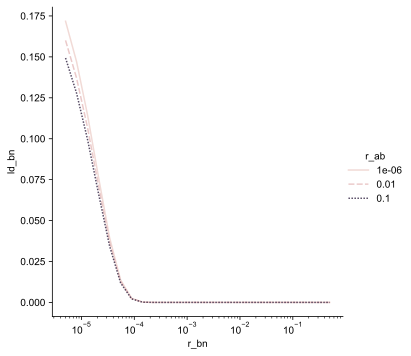

In [147]:
figfreqs = sns.relplot(data=lddf, x='r_bn', y='ld_bn', hue='r_ab',
        style='r_ab', kind="line", alpha=0.8)
plt.xscale('log')
plt.show()

neutral LD is reduced with increasing distance, not really that interesting

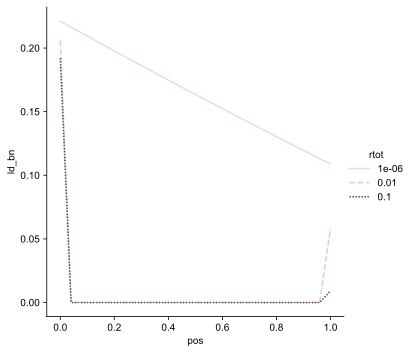

In [149]:
figfreqs = sns.relplot(data=lddf_neutb, x='pos', y='ld_bn', hue='rtot',
        style='rtot', kind="line", alpha=0.8)
plt.show()